# 30 business scenarios on a factory floor
## Finding why castings fail, and predicting failures with K-Nearest Neighbors

### The company

**Vajra Castings** is a fictional factory in Pune. It makes aluminium gearbox housings for two-wheelers using **die casting**. The flow of one part through the plant is:

1. Aluminium alloy is melted in a furnace.
2. A machine injects the liquid metal into a steel mould (called a **die**) under high pressure. One injection is called a **shot**.
3. The part cools inside the die for a few seconds and is taken out. At this point it is called a **casting**.
4. The casting goes to **CNC machining**, where it is cut to its final size. This costs ₹450 per casting.
5. The finished part goes to **final inspection**. If it has holes or cracks inside, it is **rejected** and scrapped.

### The problem

Too many parts are rejected at step 5, **after** the plant has already spent ₹450 machining them. The plant head wants two things:

- **Find out why** castings are failing.
- **Predict which castings will fail**, right after step 3, so that risky ones can be checked on an X-ray machine before any machining money is spent.

### How this notebook is organised

| Part | Scenarios | What happens |
|---|---|---|
| Part 0 | (setup) | Load the plant's data and take a first look |
| Part A | 1 to 5 | Clean the data: duplicates, messy labels, impossible readings, missing values |
| Part B | 6 to 15 | Find the causes of defects with charts |
| Part C | 16 to 17 | Find outliers and decide what to do with them |
| Part D | 18 to 22 | Prepare the data for the model: split, fill, cap, convert text to numbers, scale |
| Part E | 23 to 30 | Build KNN, tune it, and turn its predictions into a rupee decision |

**Every scenario follows the same pattern:**

- **Who is asking** and **the question**, in business words.
- **What we will do**, in data words.
- The code, with every line explained.
- **Reading the output**: what the numbers and charts say.
- **Business decision**: what the plant should do because of it.

**KNN in one sentence** (in case this is your first time): to predict the answer for a new casting, find the K past castings whose readings are most similar to it, and go with the answer most of them had.

---
# Part 0: Setup and first look

## 0.1 Import the libraries

In [1]:
# numpy: fast maths on lists of numbers.
import numpy as np

# pandas: work with data as a table of rows and columns.
import pandas as pd

# matplotlib and seaborn: draw charts.
import matplotlib.pyplot as plt
import seaborn as sns

# train_test_split: cut the table into a training part and a testing part.
# cross_val_score: test a model several times on different slices of the training data.
# cross_val_predict: the same idea, but it returns the prediction for every row instead of one score.
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict

# StandardScaler: bring every column to the same range.
from sklearn.preprocessing import StandardScaler

# KNeighborsClassifier: the KNN model.
from sklearn.neighbors import KNeighborsClassifier

# make_pipeline: join "scale" and "KNN" into one object.
from sklearn.pipeline import make_pipeline

# Tools to measure how good the predictions are.
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Three fixed colours used in every chart:
# blue = good casting, orange = defective casting (or the bar we want you to notice), grey = everything else.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#a8a79f"

# White chart background with light grid lines.
sns.set_theme(style="whitegrid")

# Show numbers with 2 decimals and commas (12,345.67) instead of scientific notation.
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Show all columns of a table instead of cutting the middle ones out.
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("Libraries are ready.")

Libraries are ready.


## 0.2 Create the plant's data file

In a real project, the factory's IT team would hand you a file exported from the machines. We do not have a real factory, so the next cell **creates** that file: `casting_production_log.csv`.

**You do not need to study this cell.** Run it once and move on. It only exists so that the notebook works on any computer. Our real work starts at 0.3, where we open the file exactly as an analyst would, without knowing what is inside.

In [2]:
# A random number generator with a fixed starting point, so everyone gets the same file.
rng = np.random.default_rng(7)

# 3,000 castings made over 75 days.
n = 3000
day = np.sort(rng.integers(0, 75, n))
date = pd.Timestamp("2026-07-01") + pd.to_timedelta(day, unit="D")

# Which machine, shift and alloy supplier each casting had.
machine = rng.choice(["DC-01", "DC-02", "DC-03", "DC-04"], n)
shift = rng.choice(["Morning", "Evening", "Night"], n, p=[0.36, 0.34, 0.30])
supplier = rng.choice(["Alloy-A", "Alloy-B", "Alloy-C"], n, p=[0.5, 0.3, 0.2])

# Tool wear: shots made on the die since its last maintenance. It climbs every day,
# and drops back to zero when the die is serviced. Each machine has its own service interval.
interval = pd.Series(machine).map({"DC-01": 40000, "DC-02": 45000, "DC-03": 95000, "DC-04": 50000}).values
offset = pd.Series(machine).map({"DC-01": 12000, "DC-02": 30000, "DC-03": 22000, "DC-04": 5000}).values
wear = ((offset + 1500 * day + rng.integers(0, 1500, n)) % interval).astype(int)

# Process readings taken for each casting.
melt = rng.normal(680, 14, n).round(1)
pressure = rng.normal(900, 50, n).round(0)
die_temp = rng.normal(200, 15, n).round(1)
cooling = rng.normal(12, 1.5, n).clip(7.5, None)
cooling = np.where(rng.uniform(0, 1, n) < 0.03, rng.uniform(30, 120, n), cooling).round(1)
vibration = (1.6 + 1.6 * wear / 100000) * rng.lognormal(0, 0.18, n)
vibration = np.where(rng.uniform(0, 1, n) < 0.03, vibration * rng.uniform(3, 12, n), vibration).round(2)
humidity = rng.normal(65, 10, n).clip(30, 95).round(0)
experience = rng.integers(0, 21, n)

# The hidden rule that decides which castings are defective (plus randomness).
risk = (-4.45
        + 0.95 * ((melt - 680) / 14) ** 2
        - 1.25 * (pressure - 900) / 50
        - 1.10 * (np.minimum(cooling, 16) - 12) / 1.5
        + 4.5 * (wear / 100000) ** 2
        + 1.3 * (np.minimum(vibration, 3.6) - 2.4)
        + 1.3 * (supplier == "Alloy-C")
        + 0.3 * (shift == "Night")
        - 0.02 * (experience - 10))
defect = (rng.uniform(0, 1, n) < 1 / (1 + np.exp(-risk))).astype(int)

# Put everything into one table.
log = pd.DataFrame({
    "part_id": [f"GH-{i:05d}" for i in range(1, n + 1)],
    "production_date": date.strftime("%Y-%m-%d"),
    "shift": shift, "machine_id": machine, "alloy_supplier": supplier,
    "melt_temperature_c": melt, "injection_pressure_bar": pressure, "die_temperature_c": die_temp,
    "cooling_time_sec": cooling, "tool_wear_shots": wear, "vibration_mm_s": vibration,
    "humidity_pct": humidity, "operator_experience_yrs": experience, "defect": defect,
})

# Real factory data is never clean. Add the kinds of problems a real logging system produces.
log.loc[rng.choice(n, 14, replace=False), "melt_temperature_c"] = 9999.0
log.loc[rng.choice(n, 7, replace=False), "melt_temperature_c"] = 0.0
log.loc[rng.choice(n, 11, replace=False), "injection_pressure_bar"] = -1.0
log.loc[rng.uniform(0, 1, n) < np.where(log["machine_id"] == "DC-02", 0.14, 0.01), "die_temperature_c"] = np.nan
log.loc[rng.uniform(0, 1, n) < 0.02, "vibration_mm_s"] = np.nan
variants = {"Morning": ["morning", "MORNING", "Morning "], "Evening": ["evening", "EVENING"], "Night": ["night", "NIGHT", "Nite"]}
messy = rng.uniform(0, 1, n) < 0.07
log.loc[messy, "shift"] = [rng.choice(variants[s]) for s in log.loc[messy, "shift"]]
log = pd.concat([log, log.iloc[rng.choice(n, 24, replace=False)]]).sort_values("part_id", kind="stable")

# Save the file. From here on, we behave as if the plant gave it to us.
log.to_csv("casting_production_log.csv", index=False)
print("File created: casting_production_log.csv")

File created: casting_production_log.csv


## 0.3 Load the file and look at it

Each row in the file is **one casting**. These are the columns the plant's system records:

| Column | Meaning |
|---|---|
| `part_id` | Serial number stamped on the casting |
| `production_date` | The day it was made |
| `shift` | Morning, Evening or Night |
| `machine_id` | Which of the 4 die-casting machines made it (DC-01 to DC-04) |
| `alloy_supplier` | Which company supplied the aluminium alloy |
| `melt_temperature_c` | Temperature of the liquid metal, in °C |
| `injection_pressure_bar` | Pressure used to push metal into the die, in bar |
| `die_temperature_c` | Temperature of the steel die, in °C |
| `cooling_time_sec` | How many seconds the part stayed in the die before removal |
| `tool_wear_shots` | Number of shots made on this die since its last maintenance |
| `vibration_mm_s` | How strongly the machine was shaking during the shot, in mm per second |
| `humidity_pct` | Air humidity in the shop, in % |
| `operator_experience_yrs` | Years of experience of the operator |
| **`defect`** | **The answer.** 1 = rejected at final inspection, 0 = passed |

In [3]:
# Read the CSV file into a table. df is the usual short name for "DataFrame", pandas' word for a table.
df = pd.read_csv("casting_production_log.csv")

# shape gives (number of rows, number of columns).
print("Rows and columns:", df.shape)

# Show the first 5 rows.
df.head()

Rows and columns: (3024, 14)


,part_id,production_date,shift,machine_id,alloy_supplier,melt_temperature_c,injection_pressure_bar,die_temperature_c,cooling_time_sec,tool_wear_shots,vibration_mm_s,humidity_pct,operator_experience_yrs,defect
0,GH-00001,2026-07-01,Morning,DC-03,Alloy-A,666.70,840.00,171.40,11.40,22097,1.59,82.00,16,0
1,GH-00002,2026-07-01,Night,DC-03,Alloy-A,705.40,907.00,209.80,10.10,22392,2.13,76.00,10,1
2,GH-00003,2026-07-01,Night,DC-02,Alloy-B,669.80,885.00,225.80,11.60,31147,1.77,66.00,12,0
3,GH-00004,2026-07-01,Night,DC-03,Alloy-A,670.60,940.00,168.10,11.70,22601,1.81,70.00,10,0
4,GH-00005,2026-07-01,Nite,DC-04,Alloy-A,679.30,838.00,197.90,13.30,6233,1.76,78.00,5,0


**Reading the output:** the file has **3,024 rows and 14 columns**. Each row is one casting. Read the first row across: part `GH-00001` was made on 1 July in the Morning shift on machine DC-03 with Alloy-A, at a melt temperature of 666.7 °C and a pressure of 840 bar, and so on. Its last column, `defect`, is 0, so it passed inspection. The second row has `defect` = 1, so that casting was rejected.

Look at the `shift` value in the fifth row: it says `Nite`, not `Night`. We have looked at only 5 rows and already found something odd. We come back to it in Scenario 2.

Two words used from here on:

- **Features** = the columns that describe how the casting was made. These are the inputs.
- **Target** = the `defect` column. This is what we want to explain and predict.

In [4]:
# info() lists every column, how many non-empty values it has, and what type of data it holds.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3024 entries, 0 to 3023
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   part_id                  3024 non-null   str    
 1   production_date          3024 non-null   str    
 2   shift                    3024 non-null   str    
 3   machine_id               3024 non-null   str    
 4   alloy_supplier           3024 non-null   str    
 5   melt_temperature_c       3024 non-null   float64
 6   injection_pressure_bar   3024 non-null   float64
 7   die_temperature_c        2904 non-null   float64
 8   cooling_time_sec         3024 non-null   float64
 9   tool_wear_shots          3024 non-null   int64  
 10  vibration_mm_s           2962 non-null   float64
 11  humidity_pct             3024 non-null   float64
 12  operator_experience_yrs  3024 non-null   int64  
 13  defect                   3024 non-null   int64  
dtypes: float64(6), int64(3), str(5)
mem

**Reading the output:** this is a list of the 14 columns.

- **`Non-Null Count`** is how many rows have a value in that column. Most columns say 3,024, which matches the number of rows. But `die_temperature_c` has only **2,904** and `vibration_mm_s` has only **2,962**. So 120 die temperature readings and 62 vibration readings are empty. We look into this in Scenario 4.
- **`Dtype`** is the type of data. `float64` is a number with decimals. `int64` is a whole number. The first five columns are text (shown as `str` or `object`, depending on your version of pandas).
- `production_date` is stored as **text**, not as a date. We will convert it in Scenario 10 when we need to do calculations with dates.

In [5]:
# describe() gives summary numbers for every numeric column. .T turns it sideways so it is easier to read.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
melt_temperature_c,"3,024.00",721.54,633.82,0.00,670.60,679.90,689.52,"9,999.00"
injection_pressure_bar,"3,024.00",896.66,73.43,-1.00,866.00,899.00,934.00,"1,066.00"
die_temperature_c,"2,904.00",199.95,14.76,151.30,189.90,199.80,210.20,249.70
cooling_time_sec,"3,024.00",13.54,10.37,7.50,11.00,12.05,13.10,118.90
tool_wear_shots,"3,024.00","28,107.18","19,560.84",20.00,"13,511.50","26,298.00","37,711.00","94,928.00"
vibration_mm_s,"2,962.00",2.49,2.59,0.96,1.74,2.03,2.39,33.60
humidity_pct,"3,024.00",64.89,9.83,30.00,58.00,65.00,71.00,95.00
operator_experience_yrs,"3,024.00",10.03,6.00,0.00,5.00,10.00,15.00,20.00
defect,"3,024.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00


**Reading the output:** each row describes one numeric column. `mean` is the average, `min` and `max` are the smallest and largest values, and `25%`, `50%`, `75%` are the values below which a quarter, a half and three quarters of the castings fall.

Compare the `75%` column with the `max` column. In a well-behaved column, the two are not far apart. Here, several rows look wrong:

| Column | 75% of castings are below | Largest value | What looks wrong |
|---|---|---|---|
| `melt_temperature_c` | 689.5 | **9,999** | The smallest value is also suspicious: **0** |
| `injection_pressure_bar` | 934 | 1,066 | The smallest value is **-1** |
| `cooling_time_sec` | 13.1 | **118.9** | Nine times larger than the 75% value |
| `vibration_mm_s` | 2.39 | **33.6** | Fourteen times larger than the 75% value |

Also notice that the **average melt temperature is 721.5 °C** while the middle value (`50%`) is 679.9 °C. A few values of 9,999 have pulled the average up by more than 40 degrees.

The last row, `defect`, has a mean of 0.16. Since the column holds only 0s and 1s, the mean is the share of 1s: about 16% of the rows are defective castings.

We now know the file needs cleaning before any business question can be answered. That is Part A.

---
# Part A: Clean the data (Scenarios 1 to 5)

Any number we report to the plant head is only as good as the data behind it. Before answering a single business question, we fix the problems in the file.

## Scenario 1: "The logger sometimes writes the same part twice"

**Who is asking:** Farhan, the data engineer who maintains the machine logging system.

**The question:** "When the network drops, the logger re-sends the last record. Are some castings counted twice in your file?"

**Why it matters to the business:** if a defective casting is counted twice, the defect rate looks worse than it is. Every count and percentage after this would be slightly wrong.

**What we will do:** each casting has a unique serial number (`part_id`). If the same `part_id` appears on more than one row, it is a duplicate. We count them, look at a few, and keep only the first copy of each.

In [6]:
# duplicated() marks a row as True if an identical part_id has already appeared above it.
is_repeat = df.duplicated(subset="part_id")

# sum() of True/False values counts the Trues.
print("Rows in the file           :", len(df))
print("Repeated rows (duplicates) :", is_repeat.sum())

# Look at one duplicated part: take the first repeated part_id and show every row that has it.
example_id = df.loc[is_repeat, "part_id"].iloc[0]
print(f"\nExample: all rows for part {example_id}")
print(df[df["part_id"] == example_id].to_string())

# drop_duplicates() keeps the first row for each part_id and removes the later copies.
# reset_index() renumbers the rows 0, 1, 2, ... after the removal.
df = df.drop_duplicates(subset="part_id").reset_index(drop=True)

print("\nRows after removing duplicates:", len(df))

Rows in the file           : 3024
Repeated rows (duplicates) : 24

Example: all rows for part GH-00029
     part_id production_date    shift machine_id alloy_supplier  melt_temperature_c  injection_pressure_bar  die_temperature_c  cooling_time_sec  tool_wear_shots  vibration_mm_s  humidity_pct  operator_experience_yrs  defect
28  GH-00029      2026-07-01  Evening      DC-02        Alloy-B              678.80                  890.00             200.90             13.00            30751            2.18         51.00                        0       0
29  GH-00029      2026-07-01  Evening      DC-02        Alloy-B              678.80                  890.00             200.90             13.00            30751            2.18         51.00                        0       0

Rows after removing duplicates: 3000


**Reading the output:** **24 rows** are repeats of a part that was already in the file. The example shows part `GH-00029` on two rows with every value identical: same date, same machine, same temperature, same everything. That is what a re-sent record looks like. After keeping one copy of each part, the file has exactly **3,000 castings**.

**Why we checked `part_id` and not the whole row:** a serial number is stamped on one physical casting. Two rows with the same serial number are the same casting, whatever the other columns say.

**Business decision:** Farhan's suspicion was right. We work with 3,000 castings from here on, and Farhan has a concrete number (24 re-sent records in 75 days) to take to the logger's vendor.

## Scenario 2: "My shift report shows eleven shifts. We only run three."

**Who is asking:** Meenal, the shift supervisor.

**The question:** "When I filter the report by shift, I see names like `night`, `NIGHT` and `Nite` as separate shifts. Can you fix this so that I can compare the three shifts properly?"

**Why it matters to the business:** a computer treats `Night` and `night` as two different things. If we compare shifts without fixing this, the Night shift's castings are split across several small groups and its numbers are wrong.

**What we will do:** list every distinct spelling in the `shift` column, standardise them, and check again.

In [7]:
# value_counts() lists every distinct value in the column and how many times it appears.
print("Shift names BEFORE cleaning:")
print(df["shift"].value_counts().to_string())

# Step 1: strip() removes spaces at the start and end ("Morning " -> "Morning").
# Step 2: title() makes the first letter capital and the rest small ("NIGHT" -> "Night").
df["shift"] = df["shift"].str.strip().str.title()

# Check what is left after the automatic clean-up.
print("\nShift names after strip + title:")
print(df["shift"].value_counts().to_string())

# Step 3: "Nite" is a spelling mistake, so no automatic rule can fix it. We replace it by hand.
df["shift"] = df["shift"].replace({"Nite": "Night"})

# Final check.
print("\nShift names AFTER cleaning:")
print(df["shift"].value_counts().to_string())

Shift names BEFORE cleaning:
shift
Morning     1077
Evening      906
Night        808
evening       38
morning       31
EVENING       30
Morning       27
Nite          25
MORNING       21
NIGHT         19
night         18

Shift names after strip + title:
shift
Morning    1156
Evening     974
Night       845
Nite         25

Shift names AFTER cleaning:
shift
Morning    1156
Evening     974
Night       870


**Reading the output:**

- **Before cleaning** there are **11 different spellings** for 3 shifts. Notice that `Morning` appears twice in the list, with 1,077 and 27 castings. They look identical on screen, but the second one has a space at the end (`"Morning "`). To a computer those are two different values.
- **After `strip()` and `title()`** the list drops to 4 values. The spaces and the capital-letter differences are gone. But `Nite` (25 castings) is still there, because it is a spelling mistake and no general rule can know that it means Night.
- **After the manual replacement** there are exactly 3 shifts: Morning 1,156, Evening 974, Night 870. These add up to 3,000.

**What to take from this:** always look at the result after an automatic clean-up. If we had stopped after `strip()` and `title()`, 25 night-shift castings would have been left out of every shift comparison.

**Business decision:** Meenal can now compare the three shifts fairly (Scenario 6). A longer-term fix is to replace the free-text shift field on the operator's screen with a drop-down list, so that these spellings cannot be entered at all.

## Scenario 3: "The furnace cannot reach 9,999 °C"

**Who is asking:** Sunita, the quality engineer.

**The question:** "Your summary table shows a melt temperature of 9,999 °C and an injection pressure of -1 bar. Aluminium boils at about 2,470 °C, and pressure cannot be negative. Are these real readings?"

**Why it matters to the business:** these are not measurements. Many sensors write a fixed code such as `9999`, `0` or `-1` when they fail to take a reading. If we leave them in, one value of 9,999 pulls the average temperature up and every later calculation that uses this column is distorted.

**What we will do:** ask the process engineers for the range each reading can physically take, find every value outside that range, and mark it as "missing" (`NaN`). We do **not** delete the row, because the other readings on that casting are still good.

| Reading | Physically possible range | Source |
|---|---|---|
| Melt temperature | 600 to 760 °C | Below 600 the alloy is not fully liquid. The furnace cuts off at 760. |
| Injection pressure | 500 to 1,300 bar | Limits of the machine's hydraulic system |

In [8]:
# The physically possible range for each reading, as given by the process engineers.
possible_range = {
    "melt_temperature_c": (600, 760),
    "injection_pressure_bar": (500, 1300),
}

# Go through the two columns one at a time.
for column, (lowest, highest) in possible_range.items():

    # A reading is impossible if it is below the lowest or above the highest possible value.
    is_impossible = (df[column] < lowest) | (df[column] > highest)

    # Show how many there are and which values they hold.
    print(f"{column}: {is_impossible.sum()} impossible readings")
    print("   values found:", df.loc[is_impossible, column].value_counts().to_dict())

    # Replace only those readings with NaN ("Not a Number" = an empty cell). The rest of the row stays.
    df.loc[is_impossible, column] = np.nan

# Check the summary again for these two columns.
print("\nAfter the fix:")
print(df[list(possible_range)].describe().T[["count", "mean", "min", "max"]].to_string())

melt_temperature_c: 21 impossible readings
   values found: {9999.0: 14, 0.0: 7}
injection_pressure_bar: 11 impossible readings
   values found: {-1.0: 11}

After the fix:
                          count   mean    min      max
melt_temperature_c     2,979.00 680.01 634.20   734.50
injection_pressure_bar 2,989.00 899.94 725.00 1,066.00


**Reading the output:**

- `melt_temperature_c` had **21 impossible readings**: 14 values of 9,999 and 7 values of 0.
- `injection_pressure_bar` had **11 impossible readings**, all of them -1.

The fact that the same few values repeat (9999, 0, -1) confirms that these are error codes written by the sensor, not measurements.

After replacing them with empty cells, the summary makes sense: melt temperature now runs from 634.2 to 734.5 °C with an **average of 680.0**, which is the furnace target. Before the fix the average was 721.5. Pressure runs from 725 to 1,066 bar with an average of 899.9.

The `count` for these two columns dropped from 3,000 to 2,979 and 2,989, because empty cells are not counted.

**Why we did not delete these 32 rows:** each of those castings still has 12 other good values, including whether it was defective. We only removed the one reading that was wrong.

**Business decision:** Sunita's question is answered: these were sensor faults. The 32 castings stay in the analysis, with a gap where the faulty reading was. We fill the gaps in Scenario 19.

## Scenario 4: "Which sensors are dropping readings?"

**Who is asking:** Prakash, the maintenance manager.

**The question:** "I have budget to fix one sensor this month. Which sensor is failing most often, and on which machine?"

**Why it matters to the business:** a missing reading is not just a data problem. It means that for that casting, nobody knew what the machine was doing. Finding where the gaps are tells maintenance exactly where to go.

**What we will do:** count the empty cells in every column, then break the worst column down by machine.

                        empty_cells  percent_of_rows
die_temperature_c               117             3.90
vibration_mm_s                   61             2.03
melt_temperature_c               21             0.70
injection_pressure_bar           11             0.37


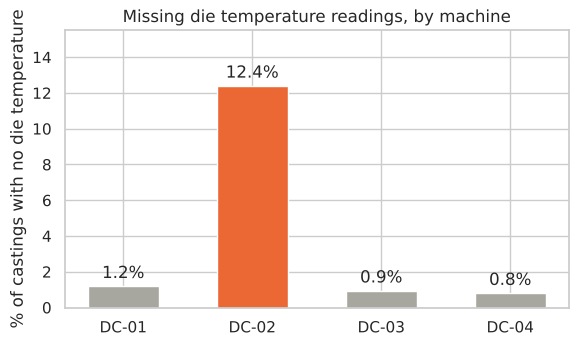

In [9]:
# isna() marks every empty cell as True. sum() counts them per column.
missing_count = df.isna().sum()

# mean() of True/False gives the share of Trues. Multiply by 100 for a percentage.
missing_percent = df.isna().mean() * 100

# Put both into one table and keep only the columns that have at least one empty cell.
missing_table = pd.DataFrame({"empty_cells": missing_count, "percent_of_rows": missing_percent})
missing_table = missing_table[missing_table["empty_cells"] > 0].sort_values("empty_cells", ascending=False)
print(missing_table.round(2).to_string())

# For the worst column, find the % of empty cells on each machine.
# groupby("machine_id") handles the rows machine by machine.
die_missing_by_machine = df["die_temperature_c"].isna().groupby(df["machine_id"]).mean() * 100

# Draw one bar per machine. The tallest bar is coloured orange.
fig, ax = plt.subplots(figsize=(6.5, 3.6))
colours = [ORANGE if value == die_missing_by_machine.max() else GREY for value in die_missing_by_machine]
bars = ax.bar(die_missing_by_machine.index, die_missing_by_machine.values, color=colours, width=0.55)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("% of castings with no die temperature")
ax.set_title("Missing die temperature readings, by machine")
ax.set_ylim(0, die_missing_by_machine.max() * 1.25)
plt.show()

**Reading the output:** four columns have empty cells.

- `die_temperature_c`: 117 empty cells (3.9% of castings). This is the worst.
- `vibration_mm_s`: 61 (2.0%).
- `melt_temperature_c`: 21 and `injection_pressure_bar`: 11. These are the error codes we turned into empty cells in Scenario 3.

The chart breaks down the missing die temperature readings by machine. On DC-01, DC-03 and DC-04, about 1% of castings have no reading. On **DC-02 it is 12.4%**, more than ten times higher.

So the 3.9% overall figure was hiding the real situation: three healthy sensors and one that is failing on one machine.

**Business decision:** Prakash should send a technician to the die temperature sensor on **DC-02** (the sensor itself or its cable). That answers his question about where to spend this month's sensor budget.

## Scenario 5: "How big is this problem, in rupees?"

**Who is asking:** Mr. Deshmukh, the plant head.

**The question:** "Before I put people on this, tell me how much money we are losing."

**Why it matters to the business:** a percentage does not get budget approved. A rupee figure does. This number also becomes the benchmark: any solution we propose must cost less than the loss it removes.

**What we will do:** now that the data is clean, count the defective castings and convert them to money using three figures from the finance team:

- **₹450** = cost of CNC machining one casting. This is wasted when the casting turns out to be defective.
- **₹90** = cost of checking one casting on the X-ray machine before machining.
- **18,00,000** = castings made per year (4 machines × 1,500 shots a day × 300 working days).

Castings in the file       : 3,000
Defective castings         : 493
Defect rate                : 16.4%
Machining money wasted     : Rs 221,850 in this file
Estimated waste per year   : Rs 133,110,000  (about Rs 13.3 crore)


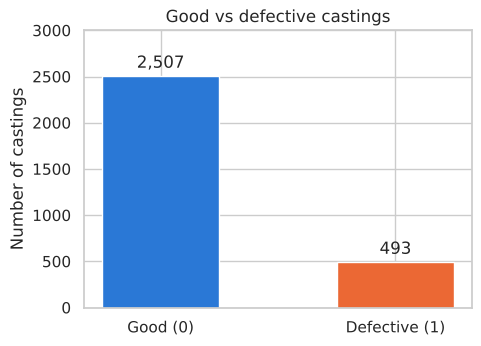

In [10]:
# Figures from the finance team. Written in capitals because they are fixed values used throughout the notebook.
MACHINING_COST = 450            # rupees wasted when a defective casting is machined
XRAY_COST = 90                  # rupees to X-ray one casting
CASTINGS_PER_YEAR = 1_800_000   # the underscore is only a visual separator, like a comma

# Count the castings and the defective ones. The defect column holds 1 for defective, so its sum is the count.
total_castings = len(df)
defective_castings = int(df["defect"].sum())

# The defect rate: defective castings as a share of all castings.
defect_rate = defective_castings / total_castings

# Money wasted on machining defective castings, in this file and scaled up to a year.
wasted_in_file = defective_castings * MACHINING_COST
wasted_per_year = CASTINGS_PER_YEAR * defect_rate * MACHINING_COST

print(f"Castings in the file       : {total_castings:,}")
print(f"Defective castings         : {defective_castings:,}")
print(f"Defect rate                : {defect_rate * 100:.1f}%")
print(f"Machining money wasted     : Rs {wasted_in_file:,.0f} in this file")
print(f"Estimated waste per year   : Rs {wasted_per_year:,.0f}  (about Rs {wasted_per_year / 1e7:.1f} crore)")

# A bar chart of good vs defective castings.
fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["Good (0)", "Defective (1)"], [total_castings - defective_castings, defective_castings],
              color=[BLUE, ORANGE], width=0.5)
ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.set_ylabel("Number of castings")
ax.set_title("Good vs defective castings")
ax.set_ylim(0, total_castings)
plt.show()

**Reading the output:** of 3,000 castings, **493 were defective**, a defect rate of **16.4%**. That is roughly 1 casting in 6.

Each defective casting was machined before it was rejected, so ₹450 was wasted on it. In this file alone that is 493 × 450 = **₹2,21,850**. Scaled up to the plant's yearly output of 18,00,000 castings, the wasted machining comes to about **₹13.3 crore a year**.

This yearly figure is an estimate. It assumes the 75 days in this file are typical of the whole year, and it counts only the machining cost. The metal can be re-melted, so we have left it out.

**Two numbers to remember from this scenario:**

- **16.4%** is the plant's overall defect rate. In Part B, every group we look at is compared against it.
- **83.6%** of castings are good. A model that says "good" for every single casting, without looking at anything, would be right 83.6% of the time. Any model we build has to beat that.

**Business decision:** Mr. Deshmukh has his figure: about ₹13 crore a year. That is large enough to justify the work in the rest of this notebook.

---
# Part B: Find the causes (Scenarios 6 to 15)

Different people in the plant have different theories about why castings fail. In this part we test each theory against the data.

**One number to keep in mind:** the overall defect rate from Scenario 5. Every chart in this part draws it as a dashed line. A bar well **above** the line is worse than the plant average. A bar well **below** it is better.

## A small helper used in several scenarios

Many scenarios ask the same kind of question: "what is the defect rate for each value of some column?" Instead of repeating the same code each time, we write it once as two small functions.

In [11]:
def defect_rate_by(column):
    # Group the castings by the given column.
    # For each group: mean of the 0/1 defect column = share defective, count = how many castings.
    table = df.groupby(column, observed=True)["defect"].agg(defect_rate="mean", castings="count")

    # Convert the share (0.16) into a percentage (16.0).
    table["defect_rate"] = table["defect_rate"] * 100

    # Hand the finished table back to whoever called the function.
    return table


def plot_defect_rate(table, title, xlabel, figsize=(7, 3.8)):
    # Create the chart area.
    fig, ax = plt.subplots(figsize=figsize)

    # The tallest bar is orange so the eye goes to it first. All others are grey.
    colours = [ORANGE if rate == table["defect_rate"].max() else GREY for rate in table["defect_rate"]]

    # One bar per group. astype(str) turns the group names into text labels for the axis.
    bars = ax.bar(table.index.astype(str), table["defect_rate"], color=colours, width=0.6)

    # Write the percentage above each bar.
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

    # The dashed line is the plant's overall defect rate, for comparison.
    ax.axhline(defect_rate * 100, color="black", linestyle="--", linewidth=1,
               label=f"Plant average ({defect_rate * 100:.1f}%)")

    # Labels, title, legend, and some empty space above the tallest bar.
    ax.set_xlabel(xlabel)
    ax.set_ylabel("% of castings defective")
    ax.set_title(title)
    ax.set_ylim(0, table["defect_rate"].max() * 1.25)
    ax.legend(loc="upper left")
    plt.show()


print("Helper functions are ready.")

Helper functions are ready.


## Scenario 6: "Everyone says the night shift makes the rejects"

**Who is asking:** Meenal, the shift supervisor.

**The question:** "The night shift gets blamed for quality in every meeting. Is that fair?"

**Why it matters to the business:** if it is true, the fix is about people: supervision, training, fatigue. If it is false, the plant is blaming the wrong team and the real cause stays hidden.

**What we will do:** calculate the defect rate for each shift and compare it with the plant average.

         defect_rate  castings
shift                         
Morning        14.60      1156
Evening        15.90       974
Night          19.40       870


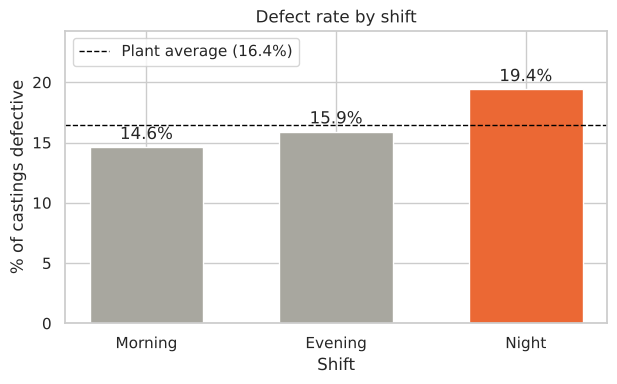

In [12]:
# Defect rate and number of castings for each shift.
by_shift = defect_rate_by("shift")

# Put the shifts in the order they happen during the day.
by_shift = by_shift.loc[["Morning", "Evening", "Night"]]

# Show the table, then the chart.
print(by_shift.round(1).to_string())
plot_defect_rate(by_shift, "Defect rate by shift", "Shift")

**Reading the output:** the defect rate is 14.6% in the Morning shift, 15.9% in the Evening and **19.4% at Night**. So the Night shift is the highest, about 3 points above the plant average and about 5 points above Morning.

Check the `castings` column before trusting the percentages: each shift has between 870 and 1,156 castings, so all three numbers rest on plenty of data.

Is the blame fair? Partly. Night is worse, but the gap is modest. Suppose the Night shift were brought down to the Morning rate of 14.6%. Its 870 castings would have about 42 fewer defects, out of 493 in total. That would remove less than a tenth of the problem.

**Business decision:** the Night shift deserves attention, but it is not the main cause. Meenal can tell the meeting that fixing Night alone would leave more than 90% of the defects in place. We keep looking.

## Scenario 7: "Is one machine making most of the rejects?"

**Who is asking:** Prakash, the maintenance manager.

**The question:** "We have four die-casting machines. Do they all produce the same quality?"

**Why it matters to the business:** if one machine is much worse, attention and money should go there first.

**What we will do:** the same calculation as Scenario 6, grouped by machine.

            defect_rate  castings
machine_id                       
DC-01             12.20       753
DC-02             12.80       766
DC-03             27.00       740
DC-04             13.90       741


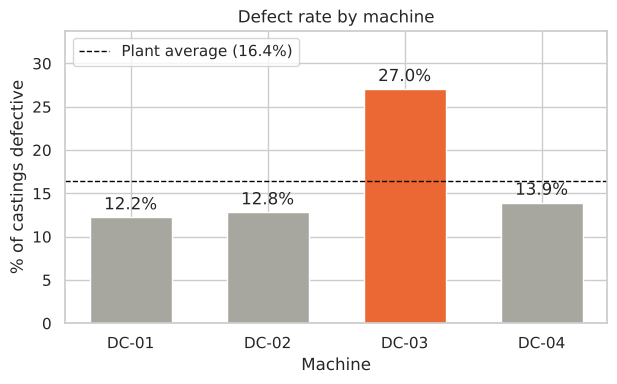

In [13]:
# Defect rate and number of castings for each machine.
by_machine = defect_rate_by("machine_id")

# Show the table, then the chart.
print(by_machine.round(1).to_string())
plot_defect_rate(by_machine, "Defect rate by machine", "Machine")

**Reading the output:** three machines are close together: DC-01 at 12.2%, DC-02 at 12.8% and DC-04 at 13.9%. All three are below the plant average. **DC-03 is at 27.0%**, about double the others.

Each machine made roughly the same number of castings (740 to 766), so the comparison is fair.

In absolute numbers, DC-03 made 740 castings and 200 of them were defective. That is **200 of the plant's 493 defects (41%) coming from one machine that makes a quarter of the output.**

**Business decision:** DC-03 is clearly where the largest share of the problem sits. This looks like a much stronger lead than the shift. But a bar chart only says **that** DC-03 is worse, not **why**. Before anyone acts on it, Scenarios 8 and 12 look at it more closely.

## Scenario 8: "Is it the machine, the shift, or one bad combination?"

**Who is asking:** Mr. Deshmukh, the plant head.

**The question:** "Scenario 6 says Night is a little worse. Scenario 7 says DC-03 is much worse. Is the real problem just DC-03 on the night shift?"

**Why it matters to the business:** looking at one column at a time can hide the real pattern. If the problem sits in one machine-shift combination, the fix is very specific. If the machine is bad in every shift, the shift is not the main issue.

**What we will do:** build a grid with machines as rows and shifts as columns. Each cell holds the defect rate for that combination. A grid coloured by value is called a **heatmap**: the darker the cell, the higher the defect rate.

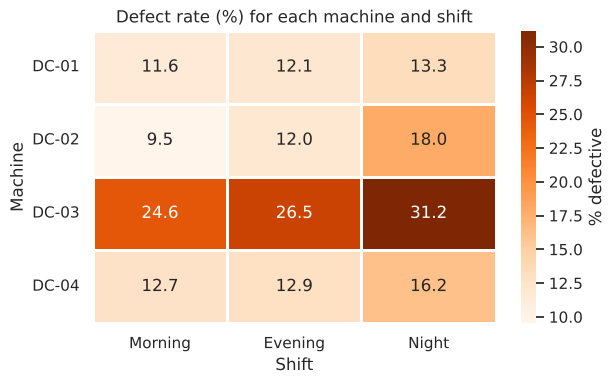

In [14]:
# pivot_table builds the grid: one row per machine, one column per shift,
# and each cell is the mean of the defect column (the share defective) for that combination.
grid = df.pivot_table(index="machine_id", columns="shift", values="defect", aggfunc="mean") * 100

# Put the shift columns in time order.
grid = grid[["Morning", "Evening", "Night"]]

# Draw the grid as a heatmap.
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(
    grid,
    annot=True,          # write the number in each cell
    fmt=".1f",           # one decimal place
    cmap="Oranges",      # light = low defect rate, dark = high
    linewidths=1,        # white lines between the cells
    cbar_kws={"label": "% defective"},
    ax=ax,
)
ax.set_title("Defect rate (%) for each machine and shift")
ax.set_xlabel("Shift")
ax.set_ylabel("Machine")
ax.tick_params(axis="y", rotation=0)    # keep the row labels horizontal
plt.show()

**Reading the output:** read the grid one row at a time.

- **DC-03's row is dark in all three shifts:** 24.6% in the Morning, 26.5% in the Evening, 31.2% at Night. Even DC-03's best shift is worse than any other machine's worst shift (the next highest cell is 18.0%).
- **The Night column is the highest in every row**, but only by a few points: for example 11.6% to 13.3% on DC-01, and 12.7% to 16.2% on DC-04.

So there are two separate effects, and they are very different in size. The machine effect is large (DC-03 is about 13 to 15 points worse than the others in every shift). The shift effect is small (Night is about 2 to 8 points worse than Morning on every machine).

The idea that the problem is "just DC-03 on the night shift" is not supported. DC-03 is bad around the clock.

**Business decision:** Mr. Deshmukh should not treat this as a night-shift staffing problem. Whatever is wrong with DC-03 is present in every shift, so it is something about the machine or how it is being run, not about who is running it.

## Scenario 9: "Should we keep buying from the cheapest alloy supplier?"

**Who is asking:** Ritu, the purchase manager.

**The question:** "Alloy-C is ₹4 per kg cheaper than the other two suppliers. Each casting uses about 1.5 kg, so that saves ₹6 per casting. The contract is up for renewal. Is their material causing more rejects?"

**Why it matters to the business:** cheap raw material is only a saving if it does not create more scrap. This is a direct purchasing decision.

**What we will do:** defect rate by supplier. Then one extra step: turn the difference into rupees per casting, so that Ritu can compare it with the saving on the alloy price.

                defect_rate  castings
alloy_supplier                       
Alloy-A               14.20      1438
Alloy-B               14.30       936
Alloy-C               24.80       626


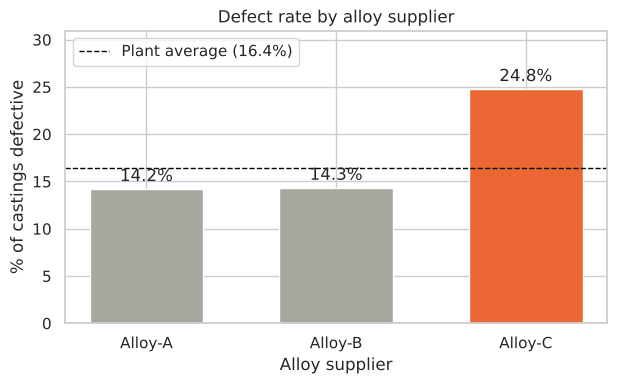

Alloy-C gives 10.6 more defective castings per 100 than Alloy-A.
Extra machining money wasted per Alloy-C casting: Rs 48


In [15]:
# Defect rate and number of castings for each supplier.
by_supplier = defect_rate_by("alloy_supplier")
print(by_supplier.round(1).to_string())
plot_defect_rate(by_supplier, "Defect rate by alloy supplier", "Alloy supplier")

# How many extra defective castings does Alloy-C produce per 100, compared with Alloy-A?
extra_defects_per_100 = by_supplier.loc["Alloy-C", "defect_rate"] - by_supplier.loc["Alloy-A", "defect_rate"]

# Each extra defective casting wastes one machining charge. Spread over 100 castings, that is the cost per casting.
extra_cost_per_casting = extra_defects_per_100 / 100 * MACHINING_COST

print(f"Alloy-C gives {extra_defects_per_100:.1f} more defective castings per 100 than Alloy-A.")
print(f"Extra machining money wasted per Alloy-C casting: Rs {extra_cost_per_casting:.0f}")

**Reading the output:** Alloy-A (14.2%) and Alloy-B (14.3%) are practically identical. **Alloy-C is at 24.8%**, about 10 points higher. All three have plenty of castings behind them (626 to 1,438).

The last two printed lines turn this into money. Alloy-C produces 10.6 more defective castings per 100 than Alloy-A. Each one wastes ₹450 of machining. Spread over all Alloy-C castings, that is an extra cost of **₹48 per casting**.

Now compare with Ritu's saving: Alloy-C is ₹4 per kg cheaper, which is **₹6 per casting**.

So the plant saves ₹6 on the purchase price and loses ₹48 in wasted machining. On every Alloy-C casting it is about ₹42 worse off.

**Business decision:** do not renew Alloy-C on the current terms. Ritu has two options: move the volume to Alloy-A and Alloy-B, or go back to the Alloy-C supplier with this data and ask for either a quality improvement or a discount of more than ₹48 per casting (about ₹32 per kg), which is unlikely. This is a case where the cheapest purchase price is the most expensive choice.

## Scenario 10: "Are we getting better or worse?"

**Who is asking:** Mr. Deshmukh, the plant head.

**The question:** "I get one defect number for the whole quarter. Was it steady, or did something happen along the way?"

**Why it matters to the business:** a single average hides events. If the defect rate jumped in certain weeks, something changed in those weeks, and finding it points to a cause.

**What we will do:** give every casting a week number (week 1 = the first 7 days of data), calculate the defect rate for each week, and draw it as a line over time.

week            1      2      3      4      5      6      7      8      9      10     11
defect_rate  12.00  13.20  18.30  16.20  18.60  26.10  24.00  12.30  14.20  14.90   9.80
castings    250.00 281.00 268.00 271.00 323.00 268.00 258.00 285.00 310.00 282.00 204.00


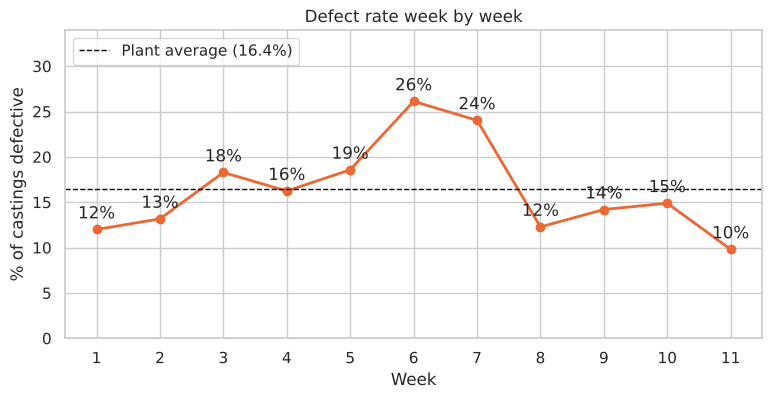

In [16]:
# Convert the date column from text into real dates, so that we can do date arithmetic on it.
df["production_date"] = pd.to_datetime(df["production_date"])

# Days since the first day in the data, divided into blocks of 7. "//" divides and drops the remainder.
# Adding 1 makes the first week "week 1" instead of "week 0".
days_since_start = (df["production_date"] - df["production_date"].min()).dt.days
df["week"] = days_since_start // 7 + 1

# Defect rate and number of castings for each week.
by_week = defect_rate_by("week")
print(by_week.round(1).T.to_string())

# Draw a line chart: weeks left to right, defect rate up and down.
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_week.index, by_week["defect_rate"], color=ORANGE, linewidth=2, marker="o")

# Write the value above each point. zip() walks through the weeks and their rates together.
for week, rate in zip(by_week.index, by_week["defect_rate"]):
    ax.annotate(f"{rate:.0f}%", (week, rate), textcoords="offset points", xytext=(0, 8), ha="center")

# The plant average as a dashed line.
ax.axhline(defect_rate * 100, color="black", linestyle="--", linewidth=1,
           label=f"Plant average ({defect_rate * 100:.1f}%)")

ax.set_xticks(by_week.index)
ax.set_xlabel("Week")
ax.set_ylabel("% of castings defective")
ax.set_title("Defect rate week by week")
ax.set_ylim(0, by_week["defect_rate"].max() * 1.3)
ax.legend(loc="upper left")
plt.show()

**Reading the output:** the defect rate was not steady.

- **Weeks 1 to 5:** between 12% and 19%, drifting upwards.
- **Weeks 6 and 7:** a clear peak at **26% and 24%**, well above the plant average.
- **Week 8:** a sudden drop to **12%**, and it stays between 10% and 15% through week 11.

The single quarterly figure of 16.4% hid all of this. The plant was at 26% in its worst week and at 10% in its best.

A drop from 24% to 12% in one week does not happen by chance with 250 to 300 castings a week. **Something changed between week 7 and week 8.**

(Week 11 has fewer castings, 204, because the data ends partway through it. Its 10% is a little less reliable than the other weeks.)

**Business decision:** Mr. Deshmukh should ask the plant: what was different from the start of week 8? If we can find what was fixed, we know what the cause was. Scenario 12 finds the answer in the data.

## Scenario 11: "After how many shots should we service the die?"

**Who is asking:** Prakash, the maintenance manager.

**The question:** "The steel die wears out a little with every shot. Servicing it means stopping the machine for a shift. Right now each machine is serviced whenever there is time. At what shot count does wear start to hurt quality?"

**Why it matters to the business:** servicing too early wastes production time. Servicing too late produces scrap. The data can show where the balance is.

**What we will do:** `tool_wear_shots` is a continuous number, so we cannot group by it directly. We first cut it into **bands** of 10,000 shots (0 to 10k, 10k to 20k, and so on), then calculate the defect rate in each band. Cutting a continuous column into ranges like this is called **binning**.

wear_band    0-10k  10-20k  20-30k  30-40k  40-50k  50-60k  60-70k  70-80k  80-90k  90-100k
defect_rate   8.30    8.50   11.50   16.20   25.50   32.30   35.70   54.90   69.40    63.00
castings    556.00  587.00  584.00  692.00  286.00   65.00   70.00   71.00   62.00    27.00


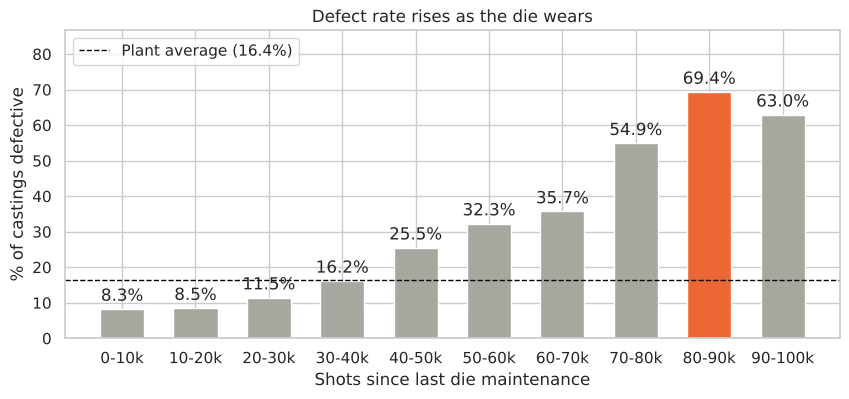

In [17]:
# The edges of the bands: 0, 10000, 20000, ..., 100000.
wear_edges = list(range(0, 100001, 10000))

# A readable label for each band: "0-10k", "10-20k", ...
wear_labels = [f"{low // 1000}-{low // 1000 + 10}k" for low in wear_edges[:-1]]

# pd.cut places each casting into the band its tool wear falls in.
# include_lowest=True makes sure a value of exactly 0 goes into the first band.
df["wear_band"] = pd.cut(df["tool_wear_shots"], bins=wear_edges, labels=wear_labels, include_lowest=True)

# Defect rate for each band.
by_wear = defect_rate_by("wear_band")
print(by_wear.round(1).T.to_string())
plot_defect_rate(by_wear, "Defect rate rises as the die wears", "Shots since last die maintenance", figsize=(10, 4))

**Reading the output:** the defect rate climbs steadily as the die wears.

- **Up to 20,000 shots:** about 8%. Half the plant average.
- **20,000 to 40,000 shots:** 11.5%, then 16.2%. Rising, and reaching the plant average.
- **40,000 to 50,000 shots:** 25.5%. A clear jump.
- **Beyond 70,000 shots:** 55% to 69%. More than half the castings are scrap.

(The last bar, 90-100k, is slightly lower than the one before it, but it rests on only 27 castings, so that small dip means nothing.)

The pattern has a visible turning point at about **40,000 shots**. Below it, the defect rate is at or under the plant average. Above it, the rate is 25% or more and keeps climbing.

In numbers: the 2,419 castings made at 40,000 shots or fewer had a defect rate of **11.4%**. The 581 castings made above 40,000 shots had a defect rate of **37.5%**. Those 581 castings are 19% of production but account for 218 of the 493 defects (44%).

**Business decision:** Prakash should set a firm rule: **service the die at or before 40,000 shots**. At 1,500 shots a day, that is one service about every 27 days per machine. A service costs one shift of lost production. Running past 40,000 costs far more than that in scrap.

## Scenario 12: "Should we replace machine DC-03?"

**Who is asking:** Anil, the finance head.

**The question:** "Scenario 7 shows DC-03 has by far the worst defect rate. A new machine costs ₹2.5 crore. Should I approve it?"

**Why it matters to the business:** this is the most expensive decision in the notebook, and it rests on one bar chart. Before spending ₹2.5 crore, we must check whether DC-03 is a bad machine, or a good machine being run in bad conditions.

**What we will do:** Scenario 11 showed that tool wear drives defects. So the fair question is: **at the same level of tool wear, is DC-03 worse than the other machines?** We build a grid with machines as rows and wear bands (20,000 shots wide) as columns. If DC-03 is a bad machine, its row will be darker than the others in every column.

Number of castings in each cell:
wear_band_wide  0-20k  20-40k  40-60k  60-80k  80-100k
machine_id                                            
DC-01             345     408       0       0        0
DC-02             328     335     103       0        0
DC-03             151     241     118     141       89
DC-04             319     292     130       0        0


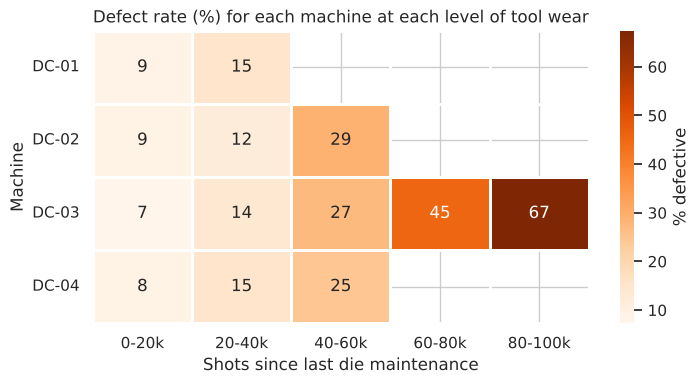

Highest tool wear reached by each machine:
machine_id
DC-01    39991
DC-02    44969
DC-03    94928
DC-04    49916

DC-03: highest tool wear in each week
week                1      2      3      4      5      6      7      8      9      10     11
tool_wear_shots  32287  42732  53325  63751  74474  84498  94928  10857  21374  31878  39415


In [18]:
# Wider bands this time (20,000 shots) so that each machine has enough castings in each band.
wide_edges = [0, 20000, 40000, 60000, 80000, 100000]
wide_labels = ["0-20k", "20-40k", "40-60k", "60-80k", "80-100k"]
df["wear_band_wide"] = pd.cut(df["tool_wear_shots"], bins=wide_edges, labels=wide_labels, include_lowest=True)

# Grid 1: the defect rate for each machine in each wear band.
rate_grid = df.pivot_table(index="machine_id", columns="wear_band_wide", values="defect",
                           aggfunc="mean", observed=True) * 100

# Grid 2: how many castings are behind each cell of grid 1.
count_grid = df.pivot_table(index="machine_id", columns="wear_band_wide", values="defect",
                            aggfunc="count", observed=True)

# Show the counts as a table. fillna(0) shows 0 where a machine never ran at that wear level.
print("Number of castings in each cell:")
print(count_grid.fillna(0).astype(int).to_string())

# Draw the defect rates as a heatmap. Cells with no castings stay blank.
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(rate_grid, annot=True, fmt=".0f", cmap="Oranges", linewidths=1,
            cbar_kws={"label": "% defective"}, ax=ax)
ax.set_title("Defect rate (%) for each machine at each level of tool wear")
ax.set_xlabel("Shots since last die maintenance")
ax.set_ylabel("Machine")
ax.tick_params(axis="y", rotation=0)    # keep the row labels horizontal
plt.show()

# The highest tool wear each machine reached in the data.
print("Highest tool wear reached by each machine:")
print(df.groupby("machine_id")["tool_wear_shots"].max().to_string())

# The highest tool wear on DC-03 in each week. .T lays the weeks out left to right.
dc03 = df[df["machine_id"] == "DC-03"]
print("\nDC-03: highest tool wear in each week")
print(dc03.groupby("week")["tool_wear_shots"].max().to_frame().T.to_string())

**Reading the output:** start with the heatmap and read it **one column at a time**. Each column compares the four machines at the same level of die wear.

- **0-20k shots:** 9%, 9%, **7%**, 8%. DC-03 is the best of the four.
- **20-40k shots:** 15%, 12%, **14%**, 15%. DC-03 is in the middle.
- **40-60k shots:** 29% (DC-02), **27%** (DC-03), 25% (DC-04). All about the same.
- **60-80k and 80-100k shots:** 45% and 67%, and **only DC-03 has any castings there.** The cells for the other machines are blank.

At the same level of tool wear, DC-03 performs exactly like the other machines. Its overall rate of 27% comes entirely from the two right-hand columns, where no other machine was ever run.

The count table and the "highest tool wear" list confirm it. DC-01, DC-02 and DC-04 were serviced at about 40,000, 45,000 and 50,000 shots. **DC-03 was run to 94,928 shots**, about twice as long as any other machine. It made 230 castings beyond 60,000 shots.

The last table shows DC-03's wear week by week: it climbs from 32,287 in week 1 to 94,928 in week 7, then drops to 10,857 in week 8. **The die on DC-03 was serviced at the start of week 8.** That is exactly when the plant's weekly defect rate fell from 24% to 12% in Scenario 10. The question raised there is now answered.

**What happened here:** in Scenario 7 we compared machines without taking tool wear into account. DC-03 looked bad because it was the only machine operating with a badly worn die. The machine was never the cause. The overdue die maintenance was.

**Business decision:** Anil should **not** approve ₹2.5 crore for a new machine. DC-03 is as good as the others. The fix is the 40,000-shot maintenance rule from Scenario 11, applied to every machine including DC-03, and it costs one shift of downtime. This one check, done before spending, saved ₹2.5 crore.

## Scenario 13: "What is the safe window for melt temperature?"

**Who is asking:** Sunita, the quality engineer.

**The question:** "The furnace operators aim for 680 °C, but the actual temperature drifts. How far can it drift before quality suffers? I want to set alarm limits on the furnace."

**Why it matters to the business:** alarm limits set too tight will stop the line for no reason. Set too loose, they let bad castings through. The data can show where the defect rate starts climbing.

**What we will do:** cut melt temperature into bands of 10 °C and calculate the defect rate in each band.

melt_band    below 655  655-665  665-675  675-685  685-695  695-705  above 705
defect_rate      53.80    21.30    11.00     9.20    10.30    25.10      57.30
castings        119.00   314.00   645.00   846.00   624.00   307.00     124.00


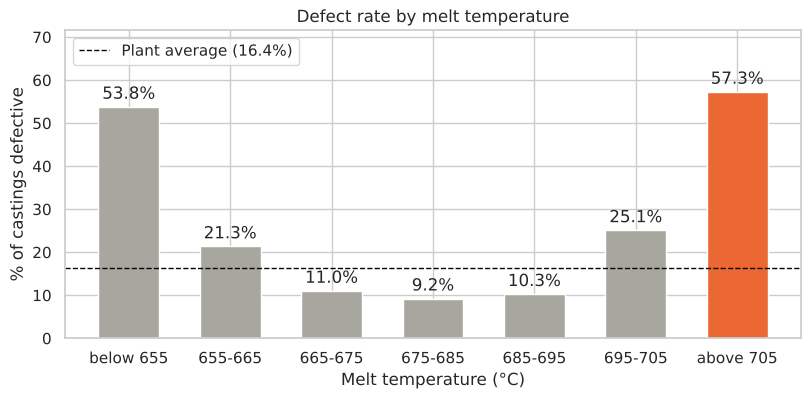

In [19]:
# Band edges in degrees C. The first and last bands are wider to collect the few extreme readings.
temp_edges = [600, 655, 665, 675, 685, 695, 705, 760]
temp_labels = ["below 655", "655-665", "665-675", "675-685", "685-695", "695-705", "above 705"]

# Place each casting in its temperature band. Castings with a missing temperature get no band and are left out.
df["melt_band"] = pd.cut(df["melt_temperature_c"], bins=temp_edges, labels=temp_labels)

# Defect rate for each band.
by_melt = defect_rate_by("melt_band")
print(by_melt.round(1).T.to_string())
plot_defect_rate(by_melt, "Defect rate by melt temperature", "Melt temperature (°C)", figsize=(9.5, 4))

**Reading the output:** the chart has a U shape.

- **In the middle, 665 to 695 °C:** the defect rate is 9% to 11%. This is well below the plant average.
- **One step out on either side (655-665 and 695-705):** it roughly doubles, to 21% and 25%.
- **At the extremes (below 655 and above 705):** 54% and 57%. More than half the castings fail.

Both directions are harmful, and by about the same amount. Metal that is too cold starts to solidify before it has filled the die. Metal that is too hot shrinks more and traps more gas as it cools.

In numbers: castings poured between 665 and 695 °C had a defect rate of **10.2%**. Castings poured outside that range had **32.3%**. About **29% of all castings** (855 of the 2,979 with a valid reading) were poured outside the range.

**Business decision:** Sunita should set the furnace alarm at **665 °C and 695 °C**, which is 15 degrees either side of the 680 target. The fact that 29% of production currently falls outside this window says that furnace temperature control is loose, and tightening it is one of the larger opportunities in the plant.

## Scenario 14: "Can we shorten the cooling time to make more parts per hour?"

**Who is asking:** Kiran, the production manager.

**The question:** "Each casting cools in the die for about 12 seconds. If I cut that to 10 seconds, every machine makes more parts per shift. Someone suggested raising the injection pressure to make up for it. Does the data support that?"

**Why it matters to the business:** this is a trade between output and quality, and it involves **two settings at once**. Looking at cooling time alone, or pressure alone, cannot answer it.

**What we will do:** cut both readings into four bands each and build a grid: cooling time down the side, pressure across the top. Each cell shows the defect rate for castings made with that combination.

Number of castings in each cell:
pressure_band  under 860  860-900  900-940  over 940
cooling_band                                        
under 10.5 s         105      149      133        82
10.5-12 s            207      318      289       215
12-13.5 s            197      298      278       218
over 13.5 s          110      147      141       102


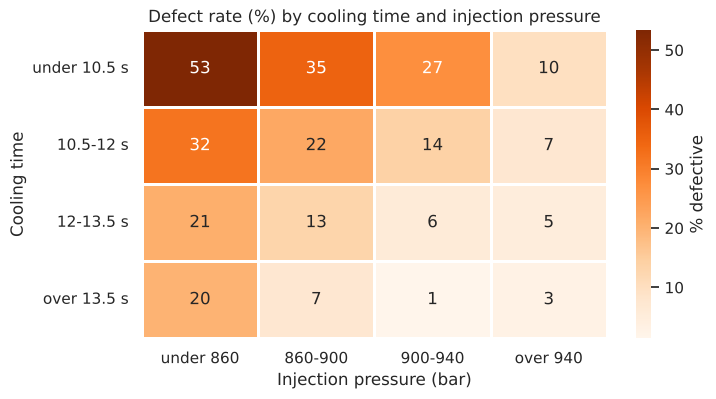

In [20]:
# Four bands for cooling time, in seconds. float("inf") means "no upper limit".
cooling_edges = [0, 10.5, 12, 13.5, float("inf")]
cooling_labels = ["under 10.5 s", "10.5-12 s", "12-13.5 s", "over 13.5 s"]
df["cooling_band"] = pd.cut(df["cooling_time_sec"], bins=cooling_edges, labels=cooling_labels)

# Four bands for injection pressure, in bar.
pressure_edges = [0, 860, 900, 940, float("inf")]
pressure_labels = ["under 860", "860-900", "900-940", "over 940"]
df["pressure_band"] = pd.cut(df["injection_pressure_bar"], bins=pressure_edges, labels=pressure_labels)

# The grid of defect rates: cooling bands as rows, pressure bands as columns.
setting_grid = df.pivot_table(index="cooling_band", columns="pressure_band", values="defect",
                              aggfunc="mean", observed=True) * 100

# The number of castings behind each cell.
setting_counts = df.pivot_table(index="cooling_band", columns="pressure_band", values="defect",
                                aggfunc="count", observed=True)
print("Number of castings in each cell:")
print(setting_counts.to_string())

# Draw the heatmap.
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(setting_grid, annot=True, fmt=".0f", cmap="Oranges", linewidths=1,
            cbar_kws={"label": "% defective"}, ax=ax)
ax.set_title("Defect rate (%) by cooling time and injection pressure")
ax.set_xlabel("Injection pressure (bar)")
ax.set_ylabel("Cooling time")
plt.show()

**Reading the output:** read the grid in two directions.

- **Down any column** (same pressure, shorter cooling as you go up): the defect rate rises. In the 860-900 bar column it goes from 7% (over 13.5 s) to 13%, 22%, and 35% (under 10.5 s). Shorter cooling means more defects.
- **Across any row** (same cooling time, higher pressure as you go right): the defect rate falls. In the top row it goes from 53% to 35%, 27% and 10%. Higher pressure means fewer defects.

The worst cell is the top-left: short cooling **and** low pressure, **53%**. The best cells are at the bottom-right: long cooling and high pressure, 1% to 5%.

Now Kiran's question. He wants to move from the 12-13.5 s row up to the "under 10.5 s" row.

- At normal pressure (860 to 940 bar), that takes the defect rate from 6-13% up to **27-35%**. That is not acceptable.
- At high pressure (over 940 bar), short cooling gives **10%**. That is below the plant average and similar to what the plant gets today with normal cooling at normal pressure.

So the data supports the suggestion: raising the pressure does make up for the shorter cooling time. But note two limits. The 10% cell rests on only 82 castings. And at the same high pressure, keeping the longer cooling time gives 5%, so the faster cycle still costs some quality.

**Why one column at a time could not answer this:** the effect of cooling time depends on the pressure. Only looking at the two together shows that.

**Business decision:** Kiran should not shorten the cooling time at the current pressure. A faster cycle is only worth trying with pressure above 940 bar, and it should start as a controlled trial on one machine, because the evidence so far is 82 castings. We test this again with the model in Scenario 30.

## Scenario 15: "Correlation says melt temperature does not matter. Shall we stop monitoring it?"

**Who is asking:** Varun, a junior analyst in the team.

**The question:** "I calculated the correlation of every reading with `defect`. Melt temperature comes out at almost zero. So it has no effect on defects and we can drop it. Right?"

**Why it matters to the business:** correlation is the most commonly used shortcut for "does X affect Y". If we trust it blindly here, the plant would stop watching one of its most important settings.

**What correlation is:** a number between -1 and +1 that measures whether two columns move together **in a straight line**.

- Close to +1: when one goes up, the other goes up.
- Close to -1: when one goes up, the other goes down.
- Close to 0: no straight-line link.

**What we will do:** calculate the correlation of each reading with `defect` and draw it. Then compare what correlation says about melt temperature with what Scenario 13 showed.

injection_pressure_bar    -0.25
cooling_time_sec          -0.08
operator_experience_yrs   -0.02
humidity_pct               0.00
melt_temperature_c         0.03
die_temperature_c          0.03
vibration_mm_s             0.15
tool_wear_shots            0.32


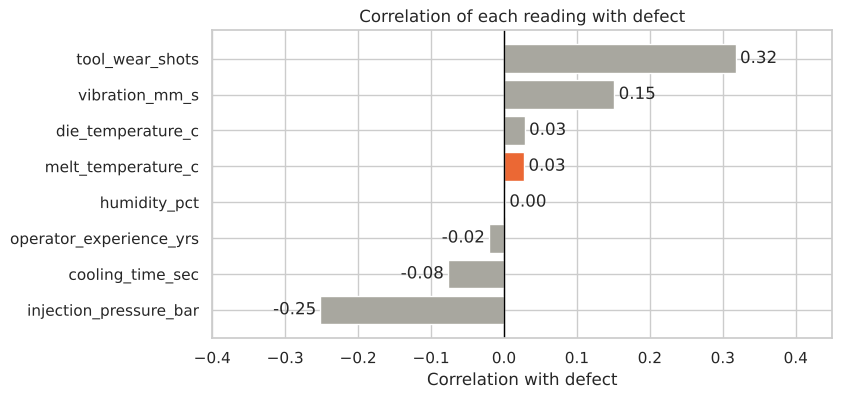

Correlation of melt temperature with defect             : 0.03
Correlation of 'distance from 680 degrees' with defect  : 0.33


In [21]:
# The eight numeric readings recorded for every casting.
numeric_columns = ["melt_temperature_c", "injection_pressure_bar", "die_temperature_c", "cooling_time_sec",
                   "tool_wear_shots", "vibration_mm_s", "humidity_pct", "operator_experience_yrs"]

# corrwith() calculates the correlation of each of these columns with the defect column.
correlation_with_defect = df[numeric_columns].corrwith(df["defect"]).sort_values()
print(correlation_with_defect.round(2).to_string())

# Draw horizontal bars: bars to the right are positive correlations, bars to the left are negative.
fig, ax = plt.subplots(figsize=(8, 4))
colours = [ORANGE if name == "melt_temperature_c" else GREY for name in correlation_with_defect.index]
bars = ax.barh(correlation_with_defect.index, correlation_with_defect.values, color=colours)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Correlation with defect")
ax.set_title("Correlation of each reading with defect")
ax.set_xlim(-0.4, 0.45)
plt.show()

# The check: instead of the temperature itself, use "how far is it from the 680 degree target, in either direction".
# abs() removes the sign, so 660 and 700 both become 20.
distance_from_target = (df["melt_temperature_c"] - 680).abs()
print(f"Correlation of melt temperature with defect             : {df['melt_temperature_c'].corr(df['defect']):.2f}")
print(f"Correlation of 'distance from 680 degrees' with defect  : {distance_from_target.corr(df['defect']):.2f}")

**Reading the output:** the bars are sorted from most negative to most positive.

- `tool_wear_shots` (**+0.32**) is the strongest. More wear, more defects. This matches Scenario 11.
- `injection_pressure_bar` (**-0.25**) is next. Higher pressure, fewer defects. This matches Scenario 14.
- `vibration_mm_s` (+0.15) and `cooling_time_sec` (-0.08) are weaker.
- `humidity_pct`, `operator_experience_yrs` and `die_temperature_c` are all within 0.03 of zero.
- **`melt_temperature_c` is +0.03.** Practically zero.

So Varun's calculation is correct. His conclusion is wrong, and Scenario 13 already showed why: castings poured below 655 °C or above 705 °C fail more than half the time. Melt temperature is one of the strongest drivers in the plant.

**Why correlation says zero:** correlation only measures a straight-line link, one where defects go steadily up (or steadily down) as temperature rises. Here the link is U-shaped: defects go **down** as temperature rises towards 680, then **up** as it rises beyond 680. The falling half and the rising half cancel each other, and the result is close to zero.

The last two printed lines prove it. When we replace the temperature with "how far is it from 680, in either direction", the U shape becomes a straight rising line, and the correlation jumps from **0.03 to 0.33**. That is slightly higher than tool wear, the strongest bar on the chart.

**Why this matters for KNN:** KNN does not use correlation at all. It finds castings with similar readings. A casting poured at 710 °C will have neighbours that were also poured hot, and many of those failed. So KNN can use a U-shaped relationship directly, without us having to create the "distance from 680" column.

**Business decision:** keep monitoring melt temperature. More generally, the team should not use correlation alone to decide which readings matter. A correlation near zero means "no straight-line link", not "no link". Always check with a band chart like the one in Scenario 13.

---
# Part C: Outliers (Scenarios 16 to 17)

An **outlier** is a value that sits far away from most other values in its column.

Outliers matter a great deal for KNN, for one reason. KNN works on **distance**, and distance is calculated from differences between values. One casting with a cooling time of 110 seconds, when all the others are near 12, is at an enormous distance from everything. It also stretches the column's range, which changes how every other casting is measured once we scale the data.

In Scenario 3 we already removed **impossible** values (sensor error codes). What is left now are values that are **possible but unusual**. These need more careful handling, because they may be telling us something real.

## Scenario 16: "Which readings are unusual?"

**Who is asking:** Sunita, the quality engineer.

**The question:** "I want a list of castings where a reading was far outside the normal range, so that I can investigate what happened on the shop floor."

**Why it matters to the business:** unusual readings are often the first sign of a real event: a line stoppage, a loose clamp, a blocked cooling channel.

**What we will do:** two things.

**1. Look at each column with a box plot.** How to read one:

- The **box** covers the middle half of the values, from the 25% point (**Q1**) to the 75% point (**Q3**). Q1 means "a quarter of the values are below this". Q3 means "three quarters are below this".
- The **line inside the box** is the median: the middle value.
- The **whiskers** (the lines sticking out of the box) reach to the furthest values that are still considered normal.
- **Dots beyond the whiskers are outliers.**

**2. Use the IQR rule to put a number on "too far".** IQR stands for interquartile range. The rule is:

- IQR = Q3 − Q1 (the width of the box)
- Lower fence = Q1 − 1.5 × IQR
- Upper fence = Q3 + 1.5 × IQR
- Any value below the lower fence or above the upper fence is an outlier.

The box plot uses this same rule to decide where the whiskers stop.

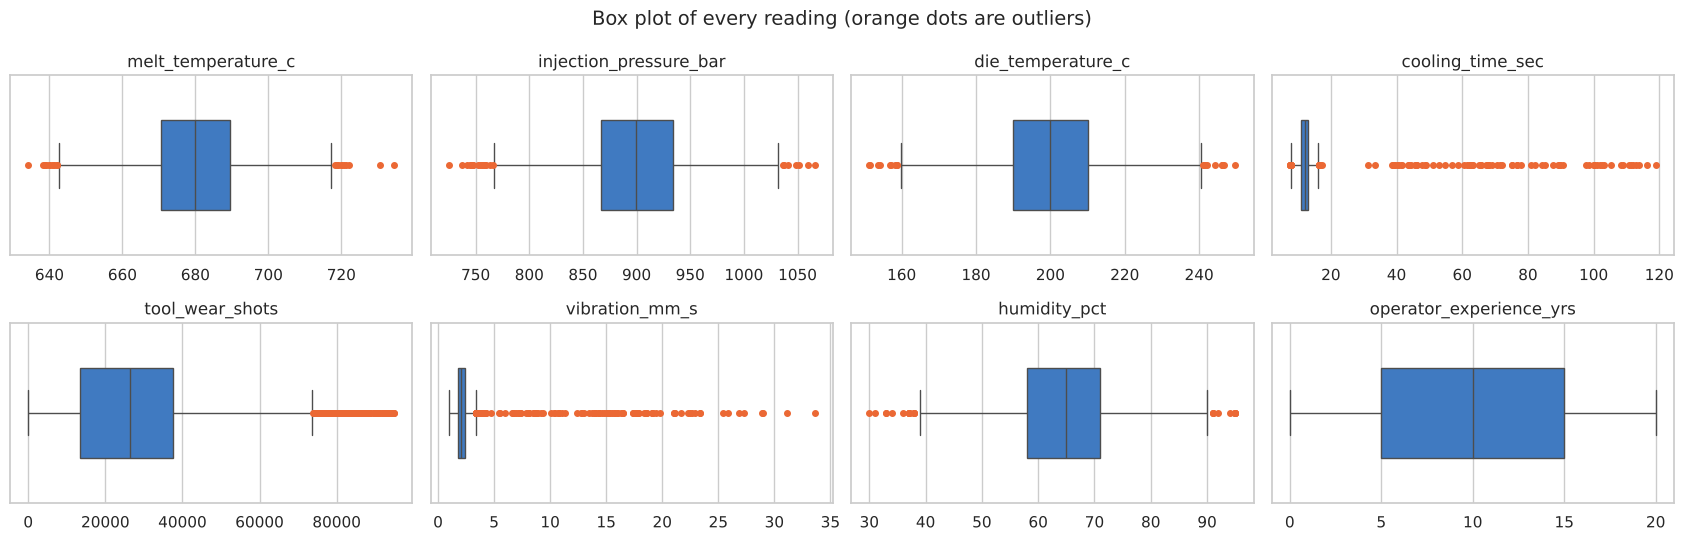

In [22]:
# A grid of 2 rows and 4 columns: one small box plot for each of the 8 numeric readings.
fig, axes = plt.subplots(2, 4, figsize=(17, 5.5))

# Pair each small chart area with one column name and draw.
for ax, column in zip(axes.flatten(), numeric_columns):

    # A horizontal box plot of this column. flierprops styles the outlier dots.
    sns.boxplot(x=df[column], color=BLUE, width=0.5, ax=ax,
                flierprops={"marker": "o", "markerfacecolor": ORANGE, "markeredgecolor": ORANGE, "markersize": 4})
    ax.set_title(column)
    ax.set_xlabel("")

fig.suptitle("Box plot of every reading (orange dots are outliers)", fontsize=14)
plt.tight_layout()
plt.show()

**Reading the output:** the eight box plots fall into three groups.

- **Compact box with a few dots on both sides:** `melt_temperature_c`, `injection_pressure_bar`, `die_temperature_c`, `humidity_pct`. The dots sit just beyond the whiskers. These are ordinary values at the edges of a normal spread.
- **No dots at all:** `operator_experience_yrs`. Every value is inside the whiskers.
- **A tiny box squeezed to the left, with a long trail of dots to the right:** `cooling_time_sec` and `vibration_mm_s`. For cooling time, the box sits near 12 seconds and the dots run all the way out to 119. For vibration, the box sits near 2 and the dots run out to 34. The box is so small that it is hard to see, because the chart has to stretch to fit the extreme values.
- **`tool_wear_shots`** is a fourth case: a wide box, and a solid block of dots from about 74,000 to 95,000. These are not scattered. They are packed tightly together.

The three columns with long trails or blocks of dots are the ones to investigate.

### The IQR rule by hand, for vibration

We now calculate the fences ourselves for one column, step by step, so that the rule is fully clear.

In [23]:
# quantile(0.25) is the value below which 25% of the castings fall (Q1). quantile(0.75) is Q3.
q1 = df["vibration_mm_s"].quantile(0.25)
q3 = df["vibration_mm_s"].quantile(0.75)

# The interquartile range: the width of the box in the box plot.
iqr = q3 - q1

# The two fences.
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Count the castings beyond each fence.
below = (df["vibration_mm_s"] < lower_fence).sum()
above = (df["vibration_mm_s"] > upper_fence).sum()

print(f"Q1 (25% point)  : {q1:.2f} mm/s")
print(f"Q3 (75% point)  : {q3:.2f} mm/s")
print(f"IQR = Q3 - Q1   : {iqr:.2f}")
print(f"Lower fence     : {q1:.2f} - 1.5 x {iqr:.2f} = {lower_fence:.2f}")
print(f"Upper fence     : {q3:.2f} + 1.5 x {iqr:.2f} = {upper_fence:.2f}")
print(f"Castings below the lower fence: {below}")
print(f"Castings above the upper fence: {above}")
print(f"Largest vibration recorded    : {df['vibration_mm_s'].max():.2f} mm/s")

Q1 (25% point)  : 1.74 mm/s
Q3 (75% point)  : 2.39 mm/s
IQR = Q3 - Q1   : 0.65
Lower fence     : 1.74 - 1.5 x 0.65 = 0.76
Upper fence     : 2.39 + 1.5 x 0.65 = 3.37
Castings below the lower fence: 0
Castings above the upper fence: 145
Largest vibration recorded    : 33.60 mm/s


**Reading the output:** for vibration, a quarter of castings are below 1.74 mm/s (Q1) and three quarters are below 2.39 mm/s (Q3). So the middle half of all castings fits in a range only **0.65 mm/s** wide. That is the IQR.

The fences are placed 1.5 times that width beyond each end of the box:

- Lower fence: 1.74 − 1.5 × 0.65 = **0.76**. No casting is below it.
- Upper fence: 2.39 + 1.5 × 0.65 = **3.37**. **145 castings** are above it.

The largest vibration recorded is 33.6 mm/s, which is ten times the upper fence.

**Why 1.5?** It is a convention. For data with an ordinary bell-shaped spread, fences at 1.5 × IQR mark fewer than 1 value in 100 as an outlier. So when 145 of 3,000 castings (almost 5%) fall outside, something more than ordinary variation is going on.

### The same rule for every column

We wrap the calculation in a function so that we can reuse it, here and again in Scenario 20.

In [24]:
def iqr_fences(values):
    # Q1 and Q3 of the given column.
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    # The width of the box.
    iqr = q3 - q1

    # Return the lower fence and the upper fence.
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


# Collect one summary row per column.
rows = []
for column in numeric_columns:

    # The two fences for this column.
    low, high = iqr_fences(df[column])

    # Count the values outside the fences.
    outliers = ((df[column] < low) | (df[column] > high)).sum()

    # Store the result as one row.
    rows.append({"reading": column, "lower_fence": low, "upper_fence": high,
                 "smallest": df[column].min(), "largest": df[column].max(),
                 "outliers": outliers, "percent_of_castings": outliers / len(df) * 100})

# Turn the list of rows into a table, largest outlier count first.
outlier_table = pd.DataFrame(rows).set_index("reading").sort_values("outliers", ascending=False)
outlier_table

,lower_fence,upper_fence,smallest,largest,outliers,percent_of_castings
reading,,,,,,
vibration_mm_s,0.76,3.37,0.96,33.60,145,4.83
tool_wear_shots,"-22,643.00","73,755.00",20.00,"94,928.00",131,4.37
cooling_time_sec,7.85,16.25,7.50,118.90,94,3.13
humidity_pct,38.50,90.50,30.00,95.00,25,0.83
melt_temperature_c,642.33,717.73,634.20,734.50,23,0.77
injection_pressure_bar,766.50,"1,034.50",725.00,"1,066.00",23,0.77
die_temperature_c,159.45,240.65,151.30,249.70,18,0.60
operator_experience_yrs,-10.00,30.00,0.00,20.00,0,0.00


**Reading the output:** the table is sorted by the number of outliers.

- **`vibration_mm_s`: 145 outliers (4.8%).** All above the upper fence of 3.37. The largest is 33.6.
- **`tool_wear_shots`: 131 outliers (4.4%).** All above 73,755 shots.
- **`cooling_time_sec`: 94 outliers (3.1%).** 83 are above the upper fence of 16.25 seconds, up to 118.9. The other 11 are just below the lower fence of 7.85.
- **The next four columns:** 18 to 25 outliers each, under 1%. This is the ordinary amount expected from a normal spread.
- **`operator_experience_yrs`: 0.**

Two fences in the table are negative (for tool wear and operator experience). A negative shot count is impossible, so those lower fences simply mean "there are no outliers on the low side".

**Business decision:** Sunita has her list. Three readings stand out: vibration, tool wear and cooling time. The next scenario decides what these outliers are and what to do with them.

## Scenario 17: "These outliers are bad data. Just delete them."

**Who is asking:** Varun, the junior analyst.

**The question:** "Outliers spoil the averages. The simplest fix is to delete every casting that has one. Can I do that?"

**Why it matters to the business:** deleting rows is easy and it is also the most common mistake in outlier handling. Before deleting anything, we need to answer one question for each outlier column: **is this a recording mistake, or did something real happen on the shop floor?**

We asked the people who run the machines:

- **Cooling time of 30 to 120 seconds:** "That is a line stoppage. When the robot that removes the part gets stuck, the casting sits in the die until someone clears it." → A real event.
- **Vibration of 8 to 30 mm/s:** "That happens when a die clamp works loose. The whole machine shakes until it is tightened." → A real event.

- **Tool wear above about 70,000 shots:** "That is DC-03 before its die was serviced. Those shot counts are correct." → A real condition.

So none of them is a recording mistake. Two questions remain for each column:

1. **Do the outlier castings behave differently from normal ones?** If yes, they carry information and deleting them throws it away.
2. **Does the size of the outlier matter?** Is a casting far beyond the fence worse than one just beyond it? This decides what we do in Scenario 20.

**What we will do:** for each column, split the castings into three groups: normal castings, the outliers nearer to the fence, and the outliers farther from it. Compare the defect rate of the three groups. Then count what we would lose by deleting all outlier castings.

cooling_time_sec: fence = 16.25, outlier castings = 83
   normal: 16.8%   |   outliers up to 65.7: 7.1%   |   outliers above 65.7: 2.4%
vibration_mm_s: fence = 3.37, outlier castings = 145
   normal: 14.9%   |   outliers up to 8.7: 53.4%   |   outliers above 8.7: 38.9%
tool_wear_shots: fence = 73,755.00, outlier castings = 131
   normal: 14.2%   |   outliers up to 83,938.0: 62.1%   |   outliers above 83,938.0: 69.2%


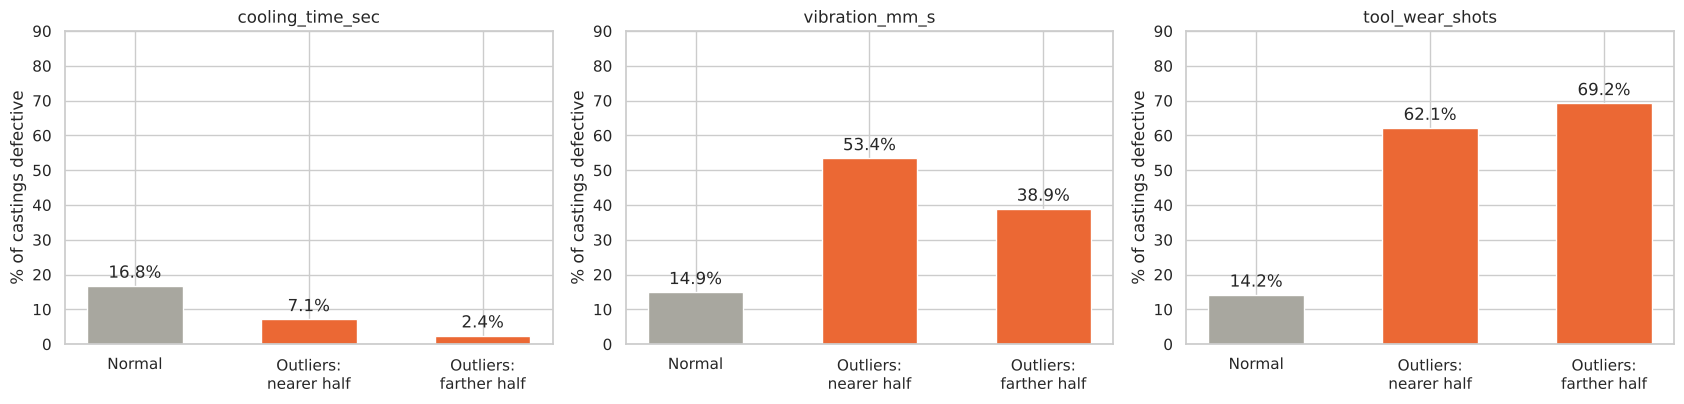


Castings with an outlier in at least one reading : 407 (13.6% of all castings)
Defective castings among them                    : 164 (33.3% of all defective castings)


In [25]:
# The three readings with the most outliers, from the table in Scenario 16.
columns_to_check = ["cooling_time_sec", "vibration_mm_s", "tool_wear_shots"]

# Three charts side by side, one per reading.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

for ax, column in zip(axes, columns_to_check):

    # The upper fence for this column, using our function from Scenario 16.
    _, upper = iqr_fences(df[column])

    # True for castings whose value is above the fence.
    is_outlier = df[column] > upper

    # Split the outlier castings into two equal halves by size:
    # those just above the fence, and those far above it. The median of the outliers is the dividing point.
    middle = df.loc[is_outlier, column].median()
    just_above = is_outlier & (df[column] <= middle)
    far_above = is_outlier & (df[column] > middle)

    # Defect rate (%) in each of the three groups. "~" means "not".
    rates = [df.loc[~is_outlier, "defect"].mean() * 100,
             df.loc[just_above, "defect"].mean() * 100,
             df.loc[far_above, "defect"].mean() * 100]

    # Print the numbers.
    print(f"{column}: fence = {upper:,.2f}, outlier castings = {is_outlier.sum()}")
    print(f"   normal: {rates[0]:.1f}%   |   outliers up to {middle:,.1f}: {rates[1]:.1f}%   |   outliers above {middle:,.1f}: {rates[2]:.1f}%")

    # Three bars: normal castings, the nearer outliers, the farther outliers.
    bars = ax.bar(["Normal", "Outliers:\nnearer half", "Outliers:\nfarther half"], rates,
                  color=[GREY, ORANGE, ORANGE], width=0.55)
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylabel("% of castings defective")
    ax.set_title(column)
    ax.set_ylim(0, 90)

plt.tight_layout()
plt.show()

# What would deleting cost? Mark every casting that has an outlier in ANY of the 8 readings.
has_any_outlier = pd.Series(False, index=df.index)
for column in numeric_columns:
    low, high = iqr_fences(df[column])
    has_any_outlier = has_any_outlier | (df[column] < low) | (df[column] > high)

print(f"\nCastings with an outlier in at least one reading : {has_any_outlier.sum()} "
      f"({has_any_outlier.mean() * 100:.1f}% of all castings)")
print(f"Defective castings among them                    : {int(df.loc[has_any_outlier, 'defect'].sum())} "
      f"({df.loc[has_any_outlier, 'defect'].sum() / df['defect'].sum() * 100:.1f}% of all defective castings)")

**Reading the output:** each chart has three bars: normal castings, the outliers nearer to the fence, and the outliers farther from it.

**Cooling time** (83 castings above 16.25 s): the normal defect rate is 16.8%. The outlier castings are at 7.1% and 2.4%. So long-cooled castings are **better** than normal, which makes sense: Scenario 14 showed that longer cooling means fewer defects. The difference between the two outlier halves (7.1% vs 2.4%) is 3 castings against 1, out of about 41 in each half. That is too few to mean anything. So: being an outlier matters, but **how far out** does not.

**Vibration** (145 castings above 3.37 mm/s): the normal defect rate is 14.9%. The outlier castings are at **53.4% and 38.9%**. These castings fail three times as often as normal ones. But the farther half is not worse than the nearer half. A casting made at 20 mm/s is no more likely to fail than one made at 5 mm/s. Again: being an outlier matters a lot, but **how far out** does not.

**Tool wear** (131 castings above 73,755 shots): normal 14.2%, outliers **62.1% and 69.2%**. Here the farther half is worse than the nearer half, and Scenario 11 showed the same steady climb across the whole range (36% at 60-70k, 55% at 70-80k, 69% at 80-90k). For tool wear, **how far out does matter**.

**What deleting would cost:** 407 castings (13.6%) have an outlier in at least one reading. They include **164 defective castings, which is a third of all the defects in the plant.** Deleting them would throw away the very castings that show what goes wrong. And there is a second, practical problem: the model will be used on live production. When a real casting comes off the machine with a vibration spike, we cannot "delete" it. It still needs a prediction.

**Business decision:** Varun's suggestion is rejected. We keep every casting. For the next step we treat the three columns differently:

| Column | Is the outlier real? | Does its size carry information? | What we do |
|---|---|---|---|
| `cooling_time_sec` | Yes, line stoppage | No | **Cap it** (Scenario 20) |
| `vibration_mm_s` | Yes, loose clamp | No | **Cap it** (Scenario 20) |
| `tool_wear_shots` | Yes, overdue maintenance | **Yes** | **Leave it exactly as it is** |

The IQR rule only points out values worth looking at. What to do with them is a decision for someone who knows the process.

---
# Part D: Prepare the data for the model (Scenarios 18 to 22)

We now move from **understanding the past** to **predicting the future**. The model will be used right after a casting comes out of the die, to predict whether it will fail final inspection.

The preparation steps happen in a fixed order, and the order matters:

`split → fill missing values → cap outliers → convert text to numbers → scale`

The split comes **first**. The next scenario explains why.

## Scenario 18: "How will you prove the model works on castings it has never seen?"

**Who is asking:** Ms. Iyer, the customer's quality auditor.

**The question:** "You will show me a model that scores well on your own data. Any model can do that. How do I know it works on parts made next month?"

**Why it matters to the business:** if a model is checked on the same castings it has stored, it looks perfect, because each casting's most similar casting is itself. That proves nothing.

**What we will do:** hide part of the data from the model.

- **Training set (80%):** the castings the model stores and uses as neighbours.
- **Test set (20%):** castings locked away until the very end. They play the role of "parts made next month".

**The rule that follows from this:** every number we calculate from data to prepare it (a median for filling gaps, a fence for capping, an average for scaling) must come from the **training set only**. Then we apply those same numbers to the test set. If the test set influenced any of them, it would no longer be a fair check. That is why the split happens before any other preparation step.

In [26]:
# Split the full table into a training table and a testing table.
train, test = train_test_split(
    df,
    test_size=0.2,           # 20% of the castings go to the test set
    random_state=42,         # fixed, so the same castings are chosen on every run
    stratify=df["defect"],   # keep the same share of defective castings in both parts
)

# Work on independent copies, so that changes to these tables never touch df.
train = train.copy()
test = test.copy()

# Check the sizes and the defect rates.
print(f"Training set: {len(train):,} castings, defect rate {train['defect'].mean() * 100:.1f}%")
print(f"Test set    : {len(test):,} castings, defect rate {test['defect'].mean() * 100:.1f}%")

# The score of a model that does nothing: it says "good" for every casting.
do_nothing_accuracy = 1 - test["defect"].mean()
print(f"\nDo-nothing accuracy on the test set (always say 'good'): {do_nothing_accuracy * 100:.1f}%")

Training set: 2,400 castings, defect rate 16.4%
Test set    : 600 castings, defect rate 16.5%

Do-nothing accuracy on the test set (always say 'good'): 83.5%


**Reading the output:** 2,400 castings go to the training set and 600 to the test set. The defect rate is 16.4% in training and 16.5% in the test set, so both parts have the same mix of good and defective castings.

**What `stratify` did:** without it, the 600 test castings are picked purely at random and could by chance contain, say, 13% or 20% defectives. Then the test would not represent normal production. `stratify=df["defect"]` forces both parts to keep the same ratio.

**The do-nothing accuracy is 83.5%.** A model that says "good" for all 600 test castings would be right 501 times. This is the number the model has to beat. It is a high bar: with only 16.5% defectives, even a useless model looks 83.5% accurate.

**A note on the method:** we split at random. In a factory, another honest option is to split by time: train on the first 60 days and test on the last 15. That checks whether a model built on the past still works on the future. Practice task 5 at the end asks you to try it.

**Business decision:** Ms. Iyer has her answer. 600 castings are locked away. Nothing in Scenarios 19 to 26 will look at them. They are opened once, in Scenario 27.

## Scenario 19: "The model must give an answer even when a sensor is down"

**Who is asking:** Kiran, the production manager.

**The question:** "Sensors drop readings every day. If your model refuses to predict whenever one reading is missing, it is useless on the floor. What will it do?"

**Why it matters to the business:** KNN calculates distance from every reading. It cannot calculate with an empty cell, so it stops with an error. We have two choices: throw away every casting with a gap, or fill the gap with a sensible value.

**What we will do:** fill each empty cell with the **median** of that column. The median is the middle value when all values are sorted.

**Why the median and not the average?** The average is pulled by extreme values. Cooling time has stoppages of over 100 seconds, which drag the average up. The median is not affected by a few extreme values, so it is a safer "typical value".

Following the rule from Scenario 18, the medians are calculated from the training set and then used to fill both sets.

In [27]:
# Count the empty cells in each numeric column of the training set, before filling.
print("Empty cells in the training set BEFORE filling:")
print(train[numeric_columns].isna().sum()[lambda counts: counts > 0].to_string())

# The median of each numeric column, calculated from the TRAINING set only.
train_medians = train[numeric_columns].median()

# To see the difference, also compute the average of cooling time.
print(f"\nCooling time: average = {train['cooling_time_sec'].mean():.2f} s, median = {train['cooling_time_sec'].median():.2f} s")

# fillna() replaces every empty cell with the median of its own column.
train[numeric_columns] = train[numeric_columns].fillna(train_medians)

# The test set is filled with the SAME training medians.
test[numeric_columns] = test[numeric_columns].fillna(train_medians)

# Confirm that no empty cells are left.
print("\nEmpty cells left in the training set:", int(train[numeric_columns].isna().sum().sum()))
print("Empty cells left in the test set    :", int(test[numeric_columns].isna().sum().sum()))

# Show the values that were used for filling.
print("\nMedians used for filling:")
print(train_medians.to_string())

Empty cells in the training set BEFORE filling:
melt_temperature_c        19
injection_pressure_bar     7
die_temperature_c         88
vibration_mm_s            52

Cooling time: average = 13.48 s, median = 12.00 s

Empty cells left in the training set: 0
Empty cells left in the test set    : 0

Medians used for filling:
melt_temperature_c           679.90
injection_pressure_bar       899.00
die_temperature_c            199.85
cooling_time_sec              12.00
tool_wear_shots           26,969.50
vibration_mm_s                 2.04
humidity_pct                  65.00
operator_experience_yrs       10.00


**Reading the output:** before filling, the training set had 88 empty die temperatures, 52 empty vibrations, 19 empty melt temperatures and 7 empty pressures. After filling, both sets have **0 empty cells**.

**Average against median for cooling time:** the average is 13.48 seconds, but the median is 12.00. The stoppages of 30 to 120 seconds pulled the average up by a second and a half. If we had filled with the average, a casting with a missing reading would be given a cooling time longer than three quarters of all castings actually had. The median, 12.0, is the typical value.

The last table lists the value used for each column: 679.9 °C for melt temperature, 899 bar for pressure, 2.04 mm/s for vibration, and so on.

**What filling does and does not do:** it lets the model give an answer when one reading is missing, using the other readings. It does not recover the lost information. A filled casting is treated as "typical" on that one reading, which may not be true.

**Business decision:** Kiran's concern is handled. When a sensor drops out, the model still predicts, using the typical value for the missing reading. If a sensor is down for long (like the die temperature sensor on DC-02 in Scenario 4), the right fix is to repair the sensor, not to rely on filling.

## Scenario 20: "Keep the stoppage castings, but stop them from distorting everything"

**Who is asking:** Sunita, the quality engineer.

**The question:** "In Scenario 17 we agreed not to delete the outliers. But you said they still cause trouble for KNN. What do we do with them?"

**Why it matters to the business:** we want to keep every casting, and keep the fact that its reading was very high. What we do not need is the exact size of the extreme value. For casting quality, a part that sat in the die for 45 seconds and one that sat for 110 seconds are in the same situation: both sat far too long. The difference between 45 and 110 only tells us how long it took someone to clear the jam.

**Which columns:** only the two where Scenario 17 showed that the size of the outlier carries no extra information: `cooling_time_sec` and `vibration_mm_s`. We leave `tool_wear_shots` exactly as it is, because there the size is the information.

**What we will do: capping.** Any value above the upper fence is replaced by the upper fence. Any value below the lower fence is replaced by the lower fence. Values inside the fences are not touched.

- A cooling time of 110 s becomes the upper fence value (about 16 s).
- A cooling time of 12.4 s stays 12.4 s.

After capping, the stoppage casting still has the **highest** cooling time in the data, so the information "this was very long" is kept. Only the exaggerated size is removed.

The fences come from the training set, and are applied to both sets.

In [28]:
# Keep a copy of both tables as they are now (filled, but NOT capped).
# We need them in Scenario 25 to test whether capping really helps the model.
train_before_capping = train.copy()
test_before_capping = test.copy()

# The two columns we decided to cap in Scenario 17.
columns_to_cap = ["cooling_time_sec", "vibration_mm_s"]

# Work out the two fences for each of them, from the TRAINING set only.
fence_rows = {}
for column in columns_to_cap:
    fence_rows[column] = iqr_fences(train[column])

# Turn them into a small table with one row per column.
fences = pd.DataFrame(fence_rows, index=["lower", "upper"]).T
print("Fences learned from the training set:")
print(fences.round(2).to_string())
print()

# clip() does the capping: values below "lower" become "lower", values above "upper" become "upper".
# axis=1 tells pandas to match each fence to its own column.
train[columns_to_cap] = train[columns_to_cap].clip(lower=fences["lower"], upper=fences["upper"], axis=1)

# The test set is capped with the SAME training fences.
test[columns_to_cap] = test[columns_to_cap].clip(lower=fences["lower"], upper=fences["upper"], axis=1)

# Compare the two outlier-heavy columns before and after capping.
for column in columns_to_cap:
    before, after = train_before_capping[column], train[column]
    print(f"{column}")
    print(f"   largest value : {before.max():7.2f} -> {after.max():.2f}")
    print(f"   average       : {before.mean():7.2f} -> {after.mean():.2f}")
    print(f"   spread (std)  : {before.std():7.2f} -> {after.std():.2f}")
    print(f"   values changed: {(before != after).sum()} of {len(before)}")

# How strongly is each column linked to defects, before and after capping?
print("\nCorrelation with defect, before -> after capping:")
for column in columns_to_cap:
    print(f"   {column:17s}: {train_before_capping[column].corr(train['defect']):+.2f} -> {train[column].corr(train['defect']):+.2f}")

Fences learned from the training set:
                  lower  upper
cooling_time_sec   8.10  16.10
vibration_mm_s     0.83   3.32

cooling_time_sec
   largest value :  116.30 -> 16.10
   average       :   13.48 -> 12.11
   spread (std)  :   10.18 -> 1.58
   values changed: 73 of 2400
vibration_mm_s
   largest value :   33.60 -> 3.32
   average       :    2.48 -> 2.12
   spread (std)  :    2.55 -> 0.51
   values changed: 125 of 2400

Correlation with defect, before -> after capping:
   cooling_time_sec : -0.07 -> -0.21
   vibration_mm_s   : +0.14 -> +0.29


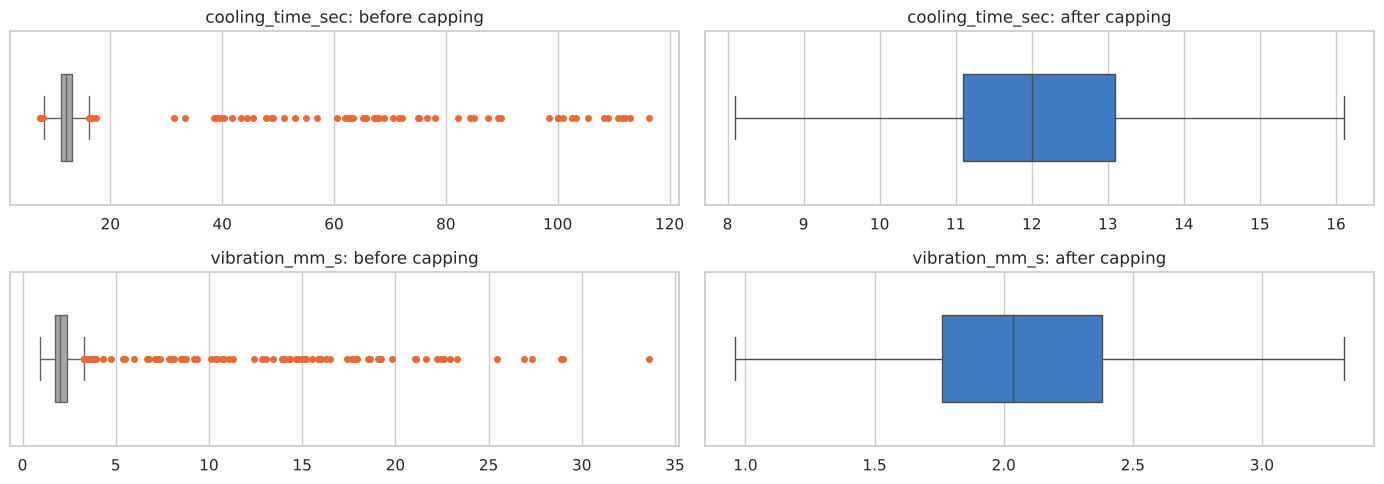

In [29]:
# Draw box plots before and after capping, for the two columns.
fig, axes = plt.subplots(2, 2, figsize=(14, 5))

for row, column in enumerate(columns_to_cap):

    # Left chart: before capping.
    sns.boxplot(x=train_before_capping[column], color=GREY, width=0.5, ax=axes[row, 0],
                flierprops={"marker": "o", "markerfacecolor": ORANGE, "markeredgecolor": ORANGE, "markersize": 4})
    axes[row, 0].set_title(f"{column}: before capping")
    axes[row, 0].set_xlabel("")

    # Right chart: after capping.
    sns.boxplot(x=train[column], color=BLUE, width=0.5, ax=axes[row, 1])
    axes[row, 1].set_title(f"{column}: after capping")
    axes[row, 1].set_xlabel("")

plt.tight_layout()
plt.show()

**Reading the output:** the first table shows the fences learned from the training set: cooling time is kept between 8.10 and 16.10 seconds, vibration between 0.83 and 3.32 mm/s.

**Cooling time:** the largest value went from 116.3 to 16.1 seconds. The average moved from 13.48 to 12.11, which is now close to the median of 12.0. The **spread fell from 10.18 to 1.58**. Only 73 of the 2,400 values were changed. The other 2,327 are untouched.

**Vibration:** the largest value went from 33.6 to 3.32. The spread fell from 2.55 to 0.51. 125 values were changed.

**The box plots** show the same thing as a picture. Before capping (left), the box is squeezed into a sliver and the chart is mostly empty space with a trail of dots. After capping (right), the box fills the chart and there are no dots. The values that were outliers are now sitting exactly on the right-hand whisker.

**The most useful lines are the last two.** They show how strongly each column is linked to defects, before and after capping:

- Cooling time: **-0.07 → -0.21**
- Vibration: **+0.14 → +0.29**

Both links became much stronger, and we did not add any information. Before capping, a handful of extreme values were hiding the pattern that the other 2,300 castings follow. Once the extremes were pulled in, the pattern became visible.

**Business decision:** Sunita's requirement is met. No casting was removed. The stoppage and loose-clamp castings are still marked as the highest values in their columns. Only the exaggerated size was removed, and the two readings are now more useful than before.

## Scenario 21: "The model cannot read the word 'Alloy-C'"

**Who is asking:** Ritu, the purchase manager.

**The question:** "Scenario 9 showed the supplier matters. I want the model to take the supplier into account. But you said KNN only works with numbers. How do you give it a name?"

**Why it matters to the business:** distance is calculated by subtracting values. "Alloy-C minus Alloy-A" has no meaning, so text columns must be converted to numbers first.

**A tempting shortcut that is wrong:** number the suppliers A = 1, B = 2, C = 3. The model would then believe that C is "three times" A, that B sits exactly between A and C, and that A and C are further apart than A and B. None of that is true. They are simply three different companies.

**What we will do: one-hot encoding.** Each category gets its own column holding 1 or 0.

| alloy_supplier | → | alloy_supplier_Alloy-A | alloy_supplier_Alloy-B | alloy_supplier_Alloy-C |
|---|---|---|---|---|
| Alloy-A | | 1 | 0 | 0 |
| Alloy-C | | 0 | 0 | 1 |

Each row has exactly one 1. No supplier is "bigger" than another. We do this for the three text columns: `shift`, `machine_id` and `alloy_supplier`.

In [30]:
# The three text columns.
text_columns = ["shift", "machine_id", "alloy_supplier"]

# get_dummies() creates one 0/1 column for every distinct value of each text column.
# dtype=int writes 1 and 0 instead of True and False.
train_dummies = pd.get_dummies(train[text_columns], dtype=int)
test_dummies = pd.get_dummies(test[text_columns], dtype=int)

# Make sure the test table has exactly the same columns, in the same order, as the training table.
# (If some category never appeared in the test set, its column is created and filled with 0.)
test_dummies = test_dummies.reindex(columns=train_dummies.columns, fill_value=0)

# Show the supplier of the first 5 training castings next to their new 0/1 columns.
supplier_columns = [name for name in train_dummies.columns if name.startswith("alloy_supplier")]
print(pd.concat([train["alloy_supplier"], train_dummies[supplier_columns]], axis=1).head().to_string())

# Build the full input tables: the 8 numeric readings side by side with the new 0/1 columns.
X_train_all = pd.concat([train[numeric_columns], train_dummies], axis=1)
X_test_all = pd.concat([test[numeric_columns], test_dummies], axis=1)

# The answers (the target) for each set.
y_train = train["defect"]
y_test = test["defect"]

print(f"\nNumber of input columns now: {X_train_all.shape[1]}")
print(list(X_train_all.columns))

     alloy_supplier  alloy_supplier_Alloy-A  alloy_supplier_Alloy-B  alloy_supplier_Alloy-C
592         Alloy-B                       0                       1                       0
2824        Alloy-A                       1                       0                       0
53          Alloy-B                       0                       1                       0
960         Alloy-C                       0                       0                       1
1150        Alloy-C                       0                       0                       1

Number of input columns now: 18
['melt_temperature_c', 'injection_pressure_bar', 'die_temperature_c', 'cooling_time_sec', 'tool_wear_shots', 'vibration_mm_s', 'humidity_pct', 'operator_experience_yrs', 'shift_Evening', 'shift_Morning', 'shift_Night', 'machine_id_DC-01', 'machine_id_DC-02', 'machine_id_DC-03', 'machine_id_DC-04', 'alloy_supplier_Alloy-A', 'alloy_supplier_Alloy-B', 'alloy_supplier_Alloy-C']


**Reading the output:** the small table shows five training castings. The first column is the original text. The next three are the new columns. The first casting used Alloy-B, so it has a 1 under `alloy_supplier_Alloy-B` and 0 in the other two. The fourth used Alloy-C, so its 1 is in the last column.

After doing this for all three text columns, the input table has **18 columns**: the 8 numeric readings, 3 shift columns, 4 machine columns and 3 supplier columns.

**Why the test table was re-aligned to the training table:** the model expects the same columns in the same order every time. If a category happened not to appear in a batch of new castings, `get_dummies` would not create its column, and the model would receive a table of the wrong shape. The `reindex` line guards against that.

**Business decision:** Ritu's request is met. The supplier is now in a form the model can use, and no supplier is treated as "larger" than another.

## Scenario 22: "Tool wear is in tens of thousands, cooling time is in seconds"

**Who is asking:** Sunita, the quality engineer.

**The question:** "You compare castings by subtracting their readings. Tool wear goes up to 95,000. Cooling time is around 12. Won't tool wear swamp everything else?"

**Why it matters to the business:** yes, it will. To a distance formula, a difference of 1,000 shots counts as 1,000 and a difference of 3 seconds of cooling counts as 3. But on the shop floor, 1,000 shots is nothing and 3 seconds of cooling is a great deal. Without a fix, the model would find "similar castings" using tool wear almost alone.

**What we will do: scaling.** We convert every column to the same unit with this formula:

$$\text{scaled value} = \frac{\text{value} - \text{column average}}{\text{column spread (standard deviation)}}$$

In words: how far is this value from the column's average, measured in units of that column's typical spread?

- 0 means exactly average.
- +1 means one typical step above average.
- -2 means two typical steps below average.

After scaling, every column mostly sits between -3 and +3, so each one gets an equal say in the distance. The averages and spreads come from the training set and are applied to both sets.

**Then we test whether it helps.** We run the same KNN model (K = 5 for now) once without scaling and once with scaling.

**How we compare two options without touching the test set: cross-validation.** The test set is locked until Scenario 27, so we cannot use it to make choices. Instead we use only the 2,400 training castings:

1. Cut the training castings into 5 equal parts of 480.
2. Store 4 parts (1,920 castings). Predict the 5th part. Note the accuracy.
3. Repeat until each of the 5 parts has been predicted once.
4. Average the 5 accuracies.

That average tells us how an option performs on castings the model did not store. We use this method for every comparison from here to Scenario 26.

**A pipeline keeps this honest.** A pipeline joins "scale" and "KNN" into one object: `raw data → StandardScaler → KNeighborsClassifier → prediction`. In each of the 5 rounds, it learns the averages and spreads from the 4 stored parts only, and it removes the risk of forgetting to scale a new casting.

In [31]:
# Create the scaler and let it learn the average and spread of each column from the TRAINING set.
scaler = StandardScaler().fit(X_train_all)

# Apply (value - average) / spread to both sets, using the training averages and spreads.
X_train_scaled = scaler.transform(X_train_all)
X_test_scaled = scaler.transform(X_test_all)

# Compare the range of a few columns before and after scaling.
range_table = pd.DataFrame({
    "min before": X_train_all.min(),
    "max before": X_train_all.max(),
    "min after": X_train_scaled.min(axis=0),
    "max after": X_train_scaled.max(axis=0),
})
print(range_table.loc[["tool_wear_shots", "injection_pressure_bar", "melt_temperature_c",
                       "cooling_time_sec", "vibration_mm_s", "alloy_supplier_Alloy-C"]].to_string())

# Option A: KNN with K = 5 on the columns as they are (no scaling).
unscaled_model = KNeighborsClassifier(n_neighbors=5)

# Option B: a pipeline that scales first and then runs the same KNN.
scaled_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# 5-fold cross-validation for each option. cv=5 means 5 parts. mean() averages the 5 accuracies.
score_all_unscaled = cross_val_score(unscaled_model, X_train_all, y_train, cv=5).mean()
score_all_scaled = cross_val_score(scaled_model, X_train_all, y_train, cv=5).mean()

# The score of doing nothing on the training set: say "good" for every casting.
do_nothing_train = 1 - y_train.mean()

print(f"\nDo-nothing accuracy (training castings)    : {do_nothing_train * 100:.1f}%")
print(f"KNN without scaling, cross-validation      : {score_all_unscaled * 100:.1f}%")
print(f"KNN with scaling, cross-validation         : {score_all_scaled * 100:.1f}%")

                        min before  max before  min after  max after
tool_wear_shots              50.00   94,835.00      -1.46       3.39
injection_pressure_bar      725.00    1,066.00      -3.52       3.36
melt_temperature_c          638.80      734.50      -2.93       3.89
cooling_time_sec              8.10       16.10      -2.54       2.53
vibration_mm_s                0.96        3.32      -2.25       2.34
alloy_supplier_Alloy-C        0.00        1.00      -0.51       1.95



Do-nothing accuracy (training castings)    : 83.6%
KNN without scaling, cross-validation      : 83.0%
KNN with scaling, cross-validation         : 85.5%


**Reading the output:** the table shows six columns before and after scaling.

- **Before:** tool wear runs from 50 to 94,835. Cooling time runs from 8.1 to 16.1. The Alloy-C column is 0 or 1. Three completely different ranges.
- **After:** every column sits roughly between -3.5 and +4.
- **Reading one value:** the highest tool wear (94,835 shots) becomes 3.39, meaning 3.39 typical steps above the average. The shortest cooling time (8.1 s) becomes -2.54.

The order of castings within each column has not changed. Only the unit has changed, from shots or seconds or bar to "steps away from the average".

**The test:**

- Do-nothing accuracy: **83.6%**
- KNN without scaling: **83.0%**. Worse than doing nothing. The model compared castings almost entirely on tool wear, because its numbers are thousands of times bigger than the others.
- KNN with scaling: **85.5%**. Now above the do-nothing line.

Scaling moved the model from "worse than useless" to "better than nothing". But 85.5% against 83.6% is still a small gain. Something else is holding the model back. The next scenario finds it.

**Business decision:** Sunita was right to ask. Scaling is required for KNN. A model built on the raw numbers would have been a tool-wear lookup and nothing more.

---
# Part E: Build the KNN model and put it to work (Scenarios 23 to 30)

The data is ready. In this part we decide which columns go into the model, look inside one prediction, check that the outlier work paid off, choose K, test the model on the locked castings, and convert its predictions into money.

Every comparison uses the two tools introduced in Scenario 22: a **pipeline** (scale, then KNN) and **cross-validation** on the training castings.

## Scenario 23: "We record 15 things about every casting. Use all of them."

**Who is asking:** Mr. Deshmukh, the plant head.

**The question:** "More information should mean better predictions. Why would you leave any column out?"

**Why it matters to the business:** for KNN, this is not true, and the reason is specific to how KNN works. KNN gives **every column an equal vote in the distance**. It has no way of learning that humidity is unimportant. If we include humidity, two castings with the same temperature, pressure and wear will look "far apart" merely because the humidity differed that day. Columns that do not affect quality add noise to the distance and push truly similar castings apart.

**What we will do:** use what we learned in Part B to choose columns, then test the choice.

| Column | What Part B showed | Keep? |
|---|---|---|
| `tool_wear_shots` | Strongest driver (Scenario 11) | Yes |
| `melt_temperature_c` | Strong, U-shaped (Scenario 13) | Yes |
| `injection_pressure_bar`, `cooling_time_sec` | Both matter (Scenario 14) | Yes |
| `vibration_mm_s` | Outlier castings fail far more often (Scenario 17) | Yes |
| `alloy_supplier` = Alloy-C | Clearly worse (Scenario 9) | Yes (the Alloy-C column) |
| `machine_id` | No effect once tool wear is known (Scenario 12) | No |
| `shift` | Small effect (Scenario 6) | No |
| `die_temperature_c`, `humidity_pct`, `operator_experience_yrs` | Correlation near zero (Scenario 15), and no pattern in a band check (first output below) | No |

Scenario 15 taught us not to drop a column on correlation alone. So before leaving out the last three columns, we check each one the way we checked melt temperature: cut it into bands and look at the defect rate in each band.

Then we compare the two sets of columns with cross-validation, each one with and without scaling.

In [32]:
# Band check for the three columns we plan to leave out.
# pd.qcut cuts a column into 4 groups with an equal number of castings: lowest quarter, second, third, highest.
for column in ["die_temperature_c", "humidity_pct", "operator_experience_yrs"]:
    quarter = pd.qcut(train[column], 4, labels=["lowest quarter", "second", "third", "highest quarter"])
    rates = train.groupby(quarter, observed=True)["defect"].mean() * 100
    print(f"{column:24s} defect rate by quarter (%):", rates.round(1).to_dict())
print()

# The six columns chosen from the Part B findings.
model_columns = ["melt_temperature_c", "injection_pressure_bar", "cooling_time_sec",
                 "tool_wear_shots", "vibration_mm_s", "alloy_supplier_Alloy-C"]

# Keep only those columns.
X_train = X_train_all[model_columns]
X_test = X_test_all[model_columns]

# The pipeline from Scenario 22 (scale, then KNN with K = 5). We keep using it until we choose K.
starter_model = scaled_model

# Cross-validation accuracy with the 6 chosen columns, with and without scaling.
score_chosen_scaled = cross_val_score(starter_model, X_train, y_train, cv=5).mean()
score_chosen_unscaled = cross_val_score(unscaled_model, X_train, y_train, cv=5).mean()

# A small table: rows = which columns, columns = scaled or not. The "all columns" numbers come from Scenario 22.
comparison = pd.DataFrame(
    {"without scaling": [score_all_unscaled * 100, score_chosen_unscaled * 100],
     "with scaling": [score_all_scaled * 100, score_chosen_scaled * 100]},
    index=[f"all {X_train_all.shape[1]} columns", f"{len(model_columns)} chosen columns"])

print(f"Do-nothing accuracy: {do_nothing_train * 100:.1f}%\n")
print("Cross-validation accuracy (%):")
print(comparison.round(1).to_string())

die_temperature_c        defect rate by quarter (%): {'lowest quarter': 15.2, 'second': 16.6, 'third': 17.8, 'highest quarter': 16.2}
humidity_pct             defect rate by quarter (%): {'lowest quarter': 16.9, 'second': 15.4, 'third': 17.3, 'highest quarter': 16.2}
operator_experience_yrs  defect rate by quarter (%): {'lowest quarter': 17.7, 'second': 18.1, 'third': 14.0, 'highest quarter': 15.7}

Do-nothing accuracy: 83.6%

Cross-validation accuracy (%):
                  without scaling  with scaling
all 18 columns              83.00         85.50
6 chosen columns            83.00         88.70


**Reading the output:**

**The band check (first three lines).** For each of the three columns we plan to leave out, the castings are split into four equal groups from lowest to highest, and the defect rate of each group is shown.

- `die_temperature_c`: 15.2%, 16.6%, 17.8%, 16.2%
- `humidity_pct`: 16.9%, 15.4%, 17.3%, 16.2%
- `operator_experience_yrs`: 17.7%, 18.1%, 14.0%, 15.7%

Every group is within 2 or 3 points of the plant average of 16.4%, and there is no steady rise, no steady fall and no U shape. Compare that with melt temperature in Scenario 13, where the bands ranged from 9% to 57%. So these three columns really do carry little or no information about defects, and it is safe to leave them out.

**The comparison table** has four numbers. The do-nothing accuracy to compare against is 83.6%.

| | without scaling | with scaling |
|---|---|---|
| all 18 columns | 83.0% | 85.5% |
| 6 chosen columns | 83.0% | **88.7%** |

- **Left column (no scaling):** 83.0% in both rows. Without scaling, it makes no difference which columns we give the model. Tool wear dominates the distance either way.
- **Right column (with scaling):** 85.5% with all columns, **88.7% with the 6 chosen ones.** Removing 12 columns made the model 3.2 points better.

The best result needs **both** steps. Scaling alone gives 85.5%. Choosing columns alone gives 83.0%. Together they give 88.7%, which is 5.1 points above doing nothing.

**Why fewer columns gave a better model:** with 18 columns, two castings with almost the same temperature, pressure, cooling time and wear could still be far apart because they were made on different machines, in different shifts, at different humidity. None of those change the quality, but each one adds to the distance. With only the 6 columns that matter, "similar" means "similar in the ways that affect quality".

**Business decision:** Mr. Deshmukh's instinct ("use everything") is reasonable for many methods, but not for KNN. We use the 6 columns that Part B showed to matter. This is also the reason Part B came before the model: the findings there told us which columns to choose.

## Scenario 24: "Show me what the model does for one casting"

**Who is asking:** Sunita, the quality engineer.

**The question:** "Before I trust this, walk me through one prediction. No library, just the steps."

**Why it matters to the business:** people on the shop floor will not act on a number from a black box. KNN's biggest practical strength is that every prediction can be traced back to actual past castings.

**What we will do:** take one casting from the test set and do the whole KNN procedure by hand:

1. Scale the casting with the training averages and spreads.
2. Calculate its distance to every one of the 2,400 training castings.
3. Sort by distance and keep the 5 nearest.
4. Count how many of the 5 were defective. The majority is the prediction.

**The distance formula (Euclidean distance)** between two castings A and B: take the difference in each of the 6 scaled columns, square each difference, add them up, and take the square root.

$$\text{distance} = \sqrt{(a_1 - b_1)^2 + (a_2 - b_2)^2 + \dots + (a_6 - b_6)^2}$$

In [33]:
# Learn the average and spread of the 6 chosen columns from the training set.
hand_scaler = StandardScaler().fit(X_train)

# Scale the whole training set. The result is a grid of 2,400 rows and 6 columns.
train_scaled = hand_scaler.transform(X_train)

# Pick one casting from the test set: among castings with heavy tool wear, take the first one.
chosen_position = int(np.where(X_test["tool_wear_shots"] > 80000)[0][0])
one_casting = X_test.iloc[[chosen_position]]     # double brackets keep it as a one-row table

print("The casting we want a prediction for:")
print(one_casting.to_string())
print("What actually happened to it (1 = defective):", int(y_test.iloc[chosen_position]))

# Step 1: scale the casting with the training averages and spreads.
one_scaled = hand_scaler.transform(one_casting)

# Step 2: the distance formula, applied to all 2,400 training castings at once.
#   (train_scaled - one_scaled) = the difference in each of the 6 columns, for every training casting
#   ** 2                        = square each difference
#   .sum(axis=1)                = add the 6 squared differences across each row
#   np.sqrt                     = take the square root
distances = np.sqrt(((train_scaled - one_scaled) ** 2).sum(axis=1))

# Step 3: argsort() returns the row positions ordered from smallest distance to largest. Keep the first 5.
nearest_positions = np.argsort(distances)[:5]

# Look up those 5 training castings and attach their distance and their real outcome.
neighbours = X_train.iloc[nearest_positions].copy()
neighbours["distance"] = distances[nearest_positions]
neighbours["defect"] = y_train.iloc[nearest_positions].values

print("\nIts 5 most similar past castings:")
print(neighbours.to_string())

# Step 4: the vote.
votes_defective = int(neighbours["defect"].sum())
print(f"\nVotes -> defective: {votes_defective}, good: {5 - votes_defective}")
print("Prediction:", "DEFECTIVE" if votes_defective >= 3 else "GOOD")

The casting we want a prediction for:
      melt_temperature_c  injection_pressure_bar  cooling_time_sec  tool_wear_shots  vibration_mm_s  alloy_supplier_Alloy-C
1559              675.70                  888.00             13.00            81877            2.56                       0
What actually happened to it (1 = defective): 0



Its 5 most similar past castings:
      melt_temperature_c  injection_pressure_bar  cooling_time_sec  tool_wear_shots  vibration_mm_s  alloy_supplier_Alloy-C  distance  defect
1630              672.60                  876.00             12.60            84356            2.70                       0      0.51       1
1333              681.60                  897.00             12.80            72308            2.82                       0      0.85       0
1342              679.30                  894.00             11.90            71847            2.62                       0      0.92       0
1455              683.10                  884.00             13.80            76701            2.83                       0      0.94       1
1699              675.10                  926.00             13.50            86540            2.31                       0      0.99       0

Votes -> defective: 2, good: 3
Prediction: GOOD


**Reading the output:** the casting we picked was poured at 675.7 °C and 888 bar, cooled for 13.0 seconds, with normal vibration (2.56) and Alloy-A or B. On those readings it looks fine. But its die had **81,877 shots** on it. It actually turned out **good**.

**Its 5 nearest neighbours:** compare each row with the casting.

- Melt temperature 672.6 to 683.1 (the casting: 675.7)
- Pressure 876 to 926 (the casting: 888)
- Cooling time 11.9 to 13.8 (the casting: 13.0)
- Tool wear 71,847 to 86,540 (the casting: 81,877)
- None used Alloy-C (same as the casting)

They match on all six columns at once. The `distance` column runs from 0.51 for the most similar casting to 0.99 for the fifth.

**The vote:** 2 of the 5 were defective, 3 were good. The majority says **GOOD**, and that is what actually happened.

Look at how close the vote was, though. Two of five very similar castings failed. This casting was at real risk, and the yes/no answer "GOOD" hides that. Scenario 29 comes back to exactly this point.

**Business decision:** Sunita can see every step: which past castings were consulted, how similar they were, and what happened to each. When the model flags a casting on the shop floor, the same list can be shown to the operator.

## Scenario 25: "Did capping the outliers help, or was it just housekeeping?"

**Who is asking:** Varun, the junior analyst.

**The question:** "We spent two scenarios on outliers. Does the model predict any better because of it? Prove it."

**Why it matters to the business:** every preparation step should earn its place. If capping makes no difference to the predictions, we should say so.

**Why capping should help KNN, in theory:** look back at Scenario 20. Before capping, the spread of cooling time was several times larger, because of a few stoppages. Scaling divides by the spread. So before capping, the normal difference between 10.5 s and 13.5 s (which matters a lot for quality, as Scenario 14 showed) is divided by a very large number and becomes tiny. Cooling time almost disappears from the distance. After capping, the spread is small again and cooling time gets its proper say.

**What we will do:** run cross-validation twice with the same 6 columns and the same model. Once on the data from before capping (saved in Scenario 20), once on the capped data. We look at accuracy, and also at how many defective castings are caught.

In [34]:
# Build the 6 input columns from the UNCAPPED copy saved in Scenario 20.
# The Alloy-C column is not a measurement, so it is the same in both versions.
X_train_uncapped = train_before_capping[model_columns[:5]].copy()
X_train_uncapped["alloy_supplier_Alloy-C"] = X_train["alloy_supplier_Alloy-C"]

# Collect the results for the two versions.
results = {}
for name, data in [("Without capping", X_train_uncapped), ("With capping", X_train)]:

    # cross_val_predict gives the out-of-sample prediction for every training casting:
    # each casting is predicted by a model that did not store it.
    predictions = cross_val_predict(starter_model, data, y_train, cv=5)

    # Accuracy, and the number of truly defective castings that were predicted as defective.
    results[name] = {
        "accuracy_%": accuracy_score(y_train, predictions) * 100,
        "defective_caught": int(((predictions == 1) & (y_train == 1)).sum()),
        "good_wrongly_flagged": int(((predictions == 1) & (y_train == 0)).sum()),
    }

# Show the two rows as a table.
capping_table = pd.DataFrame(results).T
print(capping_table.to_string())
print(f"\nDefective castings in the training set: {int(y_train.sum())}")

# The spread of cooling time used by the scaler, in each version.
print(f"\nSpread (std) of cooling time without capping: {X_train_uncapped['cooling_time_sec'].std():.2f} s")
print(f"Spread (std) of cooling time with capping   : {X_train['cooling_time_sec'].std():.2f} s")

                 accuracy_%  defective_caught  good_wrongly_flagged
Without capping       87.12            155.00                 70.00
With capping          88.71            178.00                 55.00

Defective castings in the training set: 394

Spread (std) of cooling time without capping: 10.18 s
Spread (std) of cooling time with capping   : 1.58 s


**Reading the output:** the same model, the same six columns, with one difference: whether cooling time and vibration were capped.

| | Accuracy | Defective castings caught (of 394) | Good castings wrongly flagged |
|---|---|---|---|
| Without capping | 87.1% | 155 | 70 |
| With capping | **88.7%** | **178** | **55** |

Capping improved all three numbers. Accuracy is up by 1.6 points. The model catches **23 more defective castings** and raises **15 fewer false alarms**.

**Why:** the last two lines show it. Without capping, the spread of cooling time is 10.18 seconds. Scaling divides by that. So the difference between a casting cooled for 10.5 s and one cooled for 13.5 s, which Scenario 14 showed matters a great deal, becomes 3 ÷ 10.18 = 0.29 scaled units. Almost nothing. With capping, the spread is 1.58, and the same 3-second difference becomes 3 ÷ 1.58 = 1.9 scaled units. Cooling time is now counted properly in the distance.

In short: a few stoppage values were stretching the scale so much that the model could barely tell a short cooling time from a normal one.

**A caution:** capping helped here because we chose the columns with care in Scenario 17. It is not guaranteed to help. Practice task 3 asks you to cap tool wear as well and see what happens.

**Business decision:** Varun has his proof. The outlier work was worth doing: 23 more defects caught and 15 fewer false alarms in the training castings, from a step that changed fewer than 200 values.

## Scenario 26: "How many past castings should the model consult?"

**Who is asking:** Varun, the junior analyst.

**The question:** "We have used K = 5 everywhere without a reason. Is 5 the right number of neighbours?"

**Why it matters to the business:** K changes the predictions.

- **K too small (for example 1):** the prediction copies the single most similar past casting. If that one casting was a fluke, the prediction is wrong. The model fits the stored castings perfectly but does poorly on new ones. This is called **overfitting**.
- **K too large:** castings that are not similar at all get a vote. Since most castings are good, "good" wins almost every vote and the model stops catching defects. This is called **underfitting**.

**What we will do:** try every odd K from 1 to 49 (odd, so that a two-way vote cannot tie). For each K we record two accuracies:

- **Training accuracy:** on the castings the model has stored.
- **Cross-validation accuracy:** on castings the model has not stored. This is the one we trust.

**Why stop at 49?** A common rule of thumb is to search up to about the square root of the number of training rows. The square root of 2,400 is about 49.

 K  train_accuracy_%  cv_accuracy_%
 1            100.00          86.10
 3             92.80          87.50
 5             91.50          88.70
 7             91.00          88.30
 9             90.50          88.70
11             89.50          88.20
13             89.30          88.30
15             89.20          88.00
17             88.90          87.90
19             88.90          87.70
21             88.60          87.60
23             88.40          87.50
25             88.40          87.40
27             88.00          87.40
29             87.80          87.20
31             87.60          87.20
33             87.50          87.10
35             87.50          86.80
37             87.30          86.80
39             87.40          86.80
41             87.10          86.80
43             87.20          86.70
45             87.20          86.70
47             87.00          86.50
49             87.10          86.50

Best K by cross-validation: 5 (accuracy 88.7%)


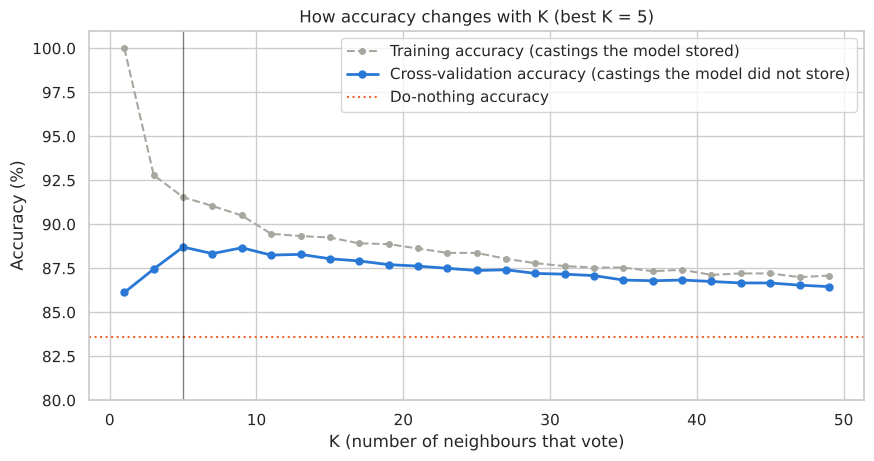

In [35]:
# The K values to try: 1, 3, 5, ..., 49.
k_values = list(range(1, 50, 2))

# Empty lists to collect the two accuracies for each K.
train_scores = []
cv_scores = []

for k in k_values:

    # A fresh pipeline (scale, then KNN) using this K.
    candidate = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

    # Training accuracy: store the 2,400 castings, then predict those same castings.
    train_scores.append(candidate.fit(X_train, y_train).score(X_train, y_train))

    # Cross-validation accuracy: the 5-part procedure.
    cv_scores.append(cross_val_score(candidate, X_train, y_train, cv=5).mean())

# Put the results into a table.
k_results = pd.DataFrame({"K": k_values,
                          "train_accuracy_%": np.array(train_scores) * 100,
                          "cv_accuracy_%": np.array(cv_scores) * 100})

# The K with the highest cross-validation accuracy.
best_k = int(k_results.loc[k_results["cv_accuracy_%"].idxmax(), "K"])
best_cv = k_results["cv_accuracy_%"].max()

print(k_results.round(1).to_string(index=False))
print(f"\nBest K by cross-validation: {best_k} (accuracy {best_cv:.1f}%)")

# Draw both accuracy lines against K.
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(k_results["K"], k_results["train_accuracy_%"], color=GREY, linestyle="--", marker="o", markersize=4,
        label="Training accuracy (castings the model stored)")
ax.plot(k_results["K"], k_results["cv_accuracy_%"], color=BLUE, linewidth=2, marker="o", markersize=5,
        label="Cross-validation accuracy (castings the model did not store)")
ax.axhline((1 - y_train.mean()) * 100, color=ORANGE, linestyle=":", label="Do-nothing accuracy")
ax.axvline(best_k, color="black", linewidth=1, alpha=0.5)
ax.set_xlabel("K (number of neighbours that vote)")
ax.set_ylabel("Accuracy (%)")
ax.set_title(f"How accuracy changes with K (best K = {best_k})")
ax.set_ylim(80, 101)
ax.legend(loc="upper right")
plt.show()

**Reading the output, from left to right on the chart:**

**At K = 1:** training accuracy (grey dashed line) is **100%**. Each stored casting's nearest neighbour is itself, so it always "predicts" its own answer. Cross-validation accuracy (blue line) is **86.1%**. The gap of 14 points between the two lines is what overfitting looks like: perfect on what it stored, much weaker on anything new.

**From K = 1 to K = 5:** the blue line climbs from 86.1% to **88.7%**. With more voters, one unusual casting can no longer decide the answer by itself.

**From K = 5 to K = 9:** the blue line stays at its peak (88.7%, 88.3%, 88.7%).

**Beyond K = 9:** the blue line slides slowly down, reaching 86.5% at K = 49. More and more voters are castings that are not very similar, and since most castings are good, their votes pull the answer towards "good".

**The best K is 5**, with 88.7%. K = 9 gives the same figure to one decimal place. Differences of 0.3 or 0.4 points here are about 8 castings out of 2,400, so the honest reading is: **any K from 5 to about 13 is equally good for a majority vote, K = 1 is clearly worse, and large K slowly loses accuracy.**

**Why 100% training accuracy should not impress anyone:** the grey line is the model checking itself on answers it already holds. Only the blue line tells us about castings it has not seen.

**Business decision:** we use K = 5 for the yes/no prediction. Keep in mind that this K was chosen for one purpose, the most accurate majority vote. Scenario 29 shows that a different purpose needs a different K.

## Scenario 27: "Open the locked box. How does it do on castings it has never seen?"

**Who is asking:** Ms. Iyer, the customer's quality auditor.

**The question:** "You have finished tuning. Now show me the result on the test castings you locked away in Scenario 18."

**Why it matters to the business:** this is the only honest measure of the model. Every choice so far (columns, capping, K) was made without looking at these 600 castings.

**What we will do:** build the final model with the best K, store all 2,400 training castings, predict the 600 test castings, and compare with what actually happened. We show the result as a **confusion matrix**: a 2 × 2 table of what actually happened (rows) against what the model predicted (columns).

| | Predicted: good | Predicted: defective |
|---|---|---|
| **Actually good** | Correct | False alarm |
| **Actually defective** | Missed defect | Correct catch |

K used               : 5
Do-nothing accuracy  : 83.5%
Model accuracy       : 86.7%


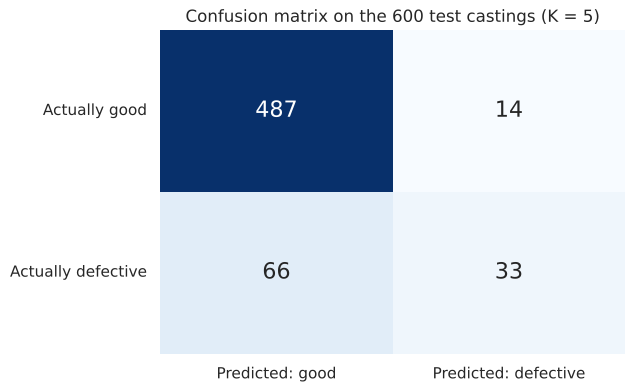

Good, predicted good            : 487
Good, predicted defective       : 14   (false alarms)
Defective, predicted good       : 66   (missed defects)
Defective, predicted defective  : 33   (caught)

               precision    recall  f1-score   support

     Good (0)       0.88      0.97      0.92       501
Defective (1)       0.70      0.33      0.45        99

     accuracy                           0.87       600
    macro avg       0.79      0.65      0.69       600
 weighted avg       0.85      0.87      0.85       600



In [36]:
# The final pipeline: scale, then KNN with the best K from Scenario 26.
final_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))

# Store all 2,400 training castings.
final_model.fit(X_train, y_train)

# Predict the 600 test castings.
test_predictions = final_model.predict(X_test)

# Accuracy against the do-nothing score.
print(f"K used               : {best_k}")
print(f"Do-nothing accuracy  : {do_nothing_accuracy * 100:.1f}%")
print(f"Model accuracy       : {accuracy_score(y_test, test_predictions) * 100:.1f}%")

# The 2x2 table: rows = what actually happened, columns = what the model predicted.
matrix = confusion_matrix(y_test, test_predictions)

# ravel() unpacks the 4 cells in reading order: top-left, top-right, bottom-left, bottom-right.
correct_good, false_alarms, missed_defects, caught_defects = matrix.ravel()

# Draw the table as a heatmap.
fig, ax = plt.subplots(figsize=(6, 4.2))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 16},
            xticklabels=["Predicted: good", "Predicted: defective"],
            yticklabels=["Actually good", "Actually defective"], ax=ax)
ax.tick_params(axis="y", rotation=0)
ax.set_title(f"Confusion matrix on the 600 test castings (K = {best_k})")
plt.show()

# The four cells in words.
print(f"Good, predicted good            : {correct_good}")
print(f"Good, predicted defective       : {false_alarms}   (false alarms)")
print(f"Defective, predicted good       : {missed_defects}   (missed defects)")
print(f"Defective, predicted defective  : {caught_defects}   (caught)")

# Precision and recall for each class.
print()
print(classification_report(y_test, test_predictions, target_names=["Good (0)", "Defective (1)"]))

**Reading the output:** on the 600 locked castings the model scores **86.7%**, against 83.5% for doing nothing. So it works on castings it has never seen. That is 3.2 points, or 19 more castings predicted correctly than "always say good".

(Cross-validation suggested 88.7% and the test gives 86.7%. A gap of 2 points on 600 castings is 12 castings. Part of it is chance. Part of it is that 88.7% was the best of 25 values of K, and the best of many tries is always slightly flattering. This is why a locked test set is needed.)

**The four cells of the confusion matrix:**

- **487** good castings predicted good. Correct.
- **14** good castings predicted defective. False alarms.
- **66** defective castings predicted good. **Missed defects.**
- **33** defective castings predicted defective. Caught.

Check: 487 + 33 = 520 correct out of 600 = 86.7%.

**The report below the matrix** gives two numbers for the defective class:

- **Recall = 0.33.** Of the 99 castings that were really defective, the model caught 33. It **misses two out of every three defects.**
- **Precision = 0.70.** Of the 47 castings it flagged, 33 were really defective. When it raises a flag, it is right 7 times in 10.

For the good class, recall is 0.97: it correctly passes 487 of 501 good castings.

**The honest summary:** 86.7% accuracy sounds good, but the plant's problem is defective castings, and the model finds only a third of them. It is cautious: it only says "defective" when at least 3 of 5 similar castings failed. Since defective castings are a minority (1 in 6), that rarely happens.

**Business decision:** Ms. Iyer can confirm the model is real: it beats the do-nothing score on unseen castings. But accuracy is the wrong number to judge it by. The next two scenarios judge it in rupees.

## Scenario 28: "Accuracy means nothing to me. What does it save?"

**Who is asking:** Anil, the finance head.

**The question:** "I do not sign off on percentages. If we use this model, how many rupees do we save compared with today?"

**Why it matters to the business:** the model does not fix castings. It only decides **which castings get an X-ray before machining**. So its value depends entirely on two costs:

- A casting the model **flags** is X-rayed: **₹90**. If the X-ray shows a defect, the casting is scrapped before machining, so the ₹450 is not wasted.
- A defective casting the model **misses** goes to machining: **₹450 wasted**, as happens today.

**What we will do:** calculate the cost of three options on the 600 test castings, and express each as rupees per 1,000 castings so that they are easy to compare.

| Option | X-ray cost | Wasted machining |
|---|---|---|
| A. Today: no X-ray at all | 0 | every defective casting × ₹450 |
| B. X-ray every casting | every casting × ₹90 | 0 |
| C. X-ray only what the model flags (majority vote) | flagged castings × ₹90 | missed defects × ₹450 |

(We assume the X-ray always finds a defect when there is one.)

Model flags 47 castings -> X-ray cost  : 47 x 90 = Rs 4,230
Model misses 66 defects -> wasted     : 66 x 450 = Rs 29,700

A. No X-ray (today)             : Rs 74,250 per 1,000 castings
B. X-ray every casting          : Rs 90,000 per 1,000 castings
C. Model, majority vote         : Rs 56,550 per 1,000 castings


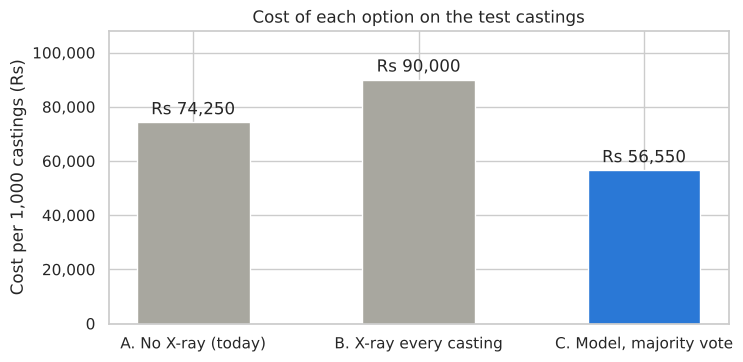

In [37]:
# The number of test castings and how many of them are truly defective.
number_of_castings = len(y_test)
number_defective = int(y_test.sum())

# Option A: no X-ray. Every defective casting is machined and the money is wasted.
cost_no_check = number_defective * MACHINING_COST

# Option B: X-ray everything. No machining is wasted, but every casting pays the X-ray cost.
cost_xray_all = number_of_castings * XRAY_COST

# Option C: the model. Flagged castings (correct catches + false alarms) are X-rayed.
# Missed defects still waste the machining cost.
flagged = caught_defects + false_alarms
cost_model = flagged * XRAY_COST + missed_defects * MACHINING_COST

# Convert each total into rupees per 1,000 castings.
per_thousand = {
    "A. No X-ray (today)": cost_no_check / number_of_castings * 1000,
    "B. X-ray every casting": cost_xray_all / number_of_castings * 1000,
    "C. Model, majority vote": cost_model / number_of_castings * 1000,
}

# Print the working for option C and then all three results.
print(f"Model flags {flagged} castings -> X-ray cost  : {flagged} x {XRAY_COST} = Rs {flagged * XRAY_COST:,}")
print(f"Model misses {missed_defects} defects -> wasted     : {missed_defects} x {MACHINING_COST} = Rs {missed_defects * MACHINING_COST:,}")
print()
for option, cost in per_thousand.items():
    print(f"{option:32s}: Rs {cost:,.0f} per 1,000 castings")

# Draw the three costs as bars. The cheapest bar is blue.
fig, ax = plt.subplots(figsize=(8, 3.8))
cheapest = min(per_thousand.values())
colours = [BLUE if cost == cheapest else GREY for cost in per_thousand.values()]
bars = ax.bar(list(per_thousand), list(per_thousand.values()), color=colours, width=0.5)
ax.bar_label(bars, fmt="Rs {:,.0f}", padding=3)
ax.set_ylabel("Cost per 1,000 castings (Rs)")
ax.set_title("Cost of each option on the test castings")
ax.set_ylim(0, max(per_thousand.values()) * 1.2)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")    # 80000 -> 80,000
plt.show()

**Reading the output:** the cost of each option, per 1,000 castings.

- **A. No X-ray (today): ₹74,250.** 165 defective castings in every 1,000, each wasting ₹450.
- **B. X-ray every casting: ₹90,000.** Nothing is wasted on machining, but 1,000 X-rays at ₹90 cost more than the waste they prevent. Checking everything is **worse than checking nothing.**
- **C. Model with majority vote: ₹56,550.** The cheapest of the three.

**The working for option C**, on the 600 test castings: the model flagged 47 castings, so 47 × ₹90 = ₹4,230 in X-rays. It missed 66 defects, so 66 × ₹450 = ₹29,700 in wasted machining. Together ₹33,930 for 600 castings, which is ₹56,550 per 1,000.

So the model saves ₹17,700 per 1,000 castings against today, a reduction of 24%.

**But look at where option C's cost comes from.** ₹29,700 of the ₹33,930 (88%) is wasted machining on the 66 missed defects. Only ₹4,230 is X-ray cost. The model is spending very little on checking and losing a great deal on misses. It is being too careful about raising a flag.

**Business decision:** Anil can see that the model already saves money, and that blanket X-ray inspection would lose money. He can also see that the remaining cost is almost entirely missed defects. That leads straight to his next question.

## Scenario 29: "A missed defect costs five times an X-ray. Why wait for a majority?"

**Who is asking:** Anil, the finance head.

**The question:** "Your model only flags a casting when more than half of its neighbours were defective. But an X-ray costs ₹90 and a miss costs ₹450. I would happily X-ray a casting that has a 1-in-3 chance of being bad. Can the model do that?"

**Why it matters to the business:** it can, and this is where most of the money is. The majority vote treats both kinds of mistake as equally bad. They are not.

**The idea:** for each casting, KNN can report the **share of neighbours that were defective**. With K neighbours, if 6 were defective, the share is 6 ÷ K. So far we flagged a casting only when the share was above 50%. We can choose a different cut-off, called the **threshold**.

**What the costs say the threshold should be:** X-raying a casting is worth it when the expected waste from not checking is more than the X-ray cost.

- Expected waste = (chance of defect) × ₹450
- X-ray cost = ₹90
- Worth checking when: chance × 450 > 90, which means **chance > 20%**

**One more thing has to change: K.** With K = 5, the share can only be 0%, 20%, 40%, 60%, 80% or 100%. That is too coarse to find a cut-off near 20%. With more neighbours, the share becomes a finer and steadier estimate: with K = 31 it can take 32 different values. In Scenario 26 we chose K for the best yes/no majority vote. Now the model has a different job (estimate a risk share), so we choose K again, this time for the lowest cost.

**What we will do:** try several values of K, and for each K try every possible threshold. For each combination, calculate the cost per 1,000 castings. Pick the combination with the lowest cost. To keep the test set honest, all of this is done with cross-validation on the **training** castings.

The cheapest threshold for each K:
 K  votes_needed  threshold_%  flagged_%  defects_caught_%  cost_per_1000
 5             2        40.00      17.80             63.70      42,787.50
 9             2        22.20      25.50             74.90      41,475.00
15             3        20.00      25.40             77.90      39,187.50
21             4        19.00      23.50             75.90      39,000.00
25             5        20.00      22.10             75.10      38,287.50
31             6        19.40      21.90             76.10      37,312.50
41             7        17.10      24.20             77.90      38,137.50
49             9        18.40      22.70             76.40      37,875.00

Lowest cost overall: K = 31, flag a casting when 6 or more of its 31 neighbours were defective (threshold 19.4%)


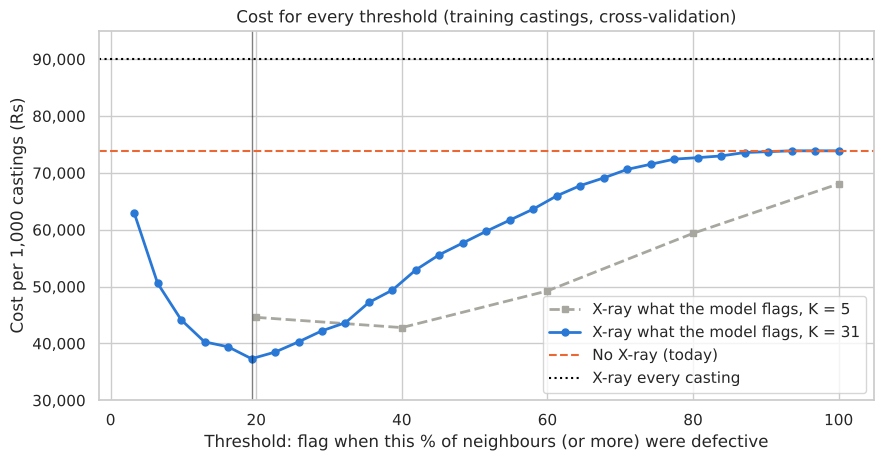

In [38]:
# The K values to try for the risk-share job.
k_candidates = [5, 9, 15, 21, 25, 31, 41, 49]

# One row will be stored for every combination of K and threshold.
combination_rows = []

for k in k_candidates:

    # A pipeline with this K.
    candidate = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

    # For every training casting, the share of its neighbours that were defective,
    # from a model that did not store that casting (cross-validation again).
    # method="predict_proba" returns two columns: [share good, share defective]. [:, 1] keeps the second.
    share = cross_val_predict(candidate, X_train, y_train, cv=5, method="predict_proba")[:, 1]

    # The possible thresholds for this K: 1 neighbour out of K, 2 out of K, ..., K out of K.
    for votes_needed in range(1, k + 1):

        # Flag a casting when its share of defective neighbours reaches the threshold.
        # The tiny 1e-9 protects against rounding errors when comparing decimals.
        flag = share >= votes_needed / k - 1e-9

        # Missed defects: truly defective castings that were not flagged.
        missed = int(((~flag) & (y_train == 1)).sum())

        # Total cost: X-ray for every flagged casting, wasted machining for every miss.
        cost = flag.sum() * XRAY_COST + missed * MACHINING_COST

        combination_rows.append({"K": k, "votes_needed": votes_needed,
                                 "threshold_%": votes_needed / k * 100,
                                 "flagged_%": flag.mean() * 100,
                                 "defects_caught_%": (1 - missed / y_train.sum()) * 100,
                                 "cost_per_1000": cost / len(y_train) * 1000})

combinations = pd.DataFrame(combination_rows)

# For each K, keep the row with the lowest cost.
best_per_k = combinations.loc[combinations.groupby("K")["cost_per_1000"].idxmin()]
print("The cheapest threshold for each K:")
print(best_per_k.round(1).to_string(index=False))

# The single cheapest combination overall.
winner = combinations.loc[combinations["cost_per_1000"].idxmin()]
cost_k = int(winner["K"])
votes_needed = int(winner["votes_needed"])
best_threshold = votes_needed / cost_k

print(f"\nLowest cost overall: K = {cost_k}, flag a casting when {votes_needed} or more "
      f"of its {cost_k} neighbours were defective (threshold {best_threshold * 100:.1f}%)")

# Draw cost against threshold for K = 5 and for the winning K.
fig, ax = plt.subplots(figsize=(10, 4.8))
for k, colour, style in [(5, GREY, "s--"), (cost_k, BLUE, "o-")]:
    rows = combinations[combinations["K"] == k]
    ax.plot(rows["threshold_%"], rows["cost_per_1000"], style, color=colour, linewidth=2, markersize=5,
            label=f"X-ray what the model flags, K = {k}")

# The two fixed alternatives as horizontal lines.
ax.axhline(y_train.mean() * MACHINING_COST * 1000, color=ORANGE, linestyle="--", label="No X-ray (today)")
ax.axhline(XRAY_COST * 1000, color="black", linestyle=":", label="X-ray every casting")

# Mark the lowest-cost threshold.
ax.axvline(best_threshold * 100, color="black", linewidth=1, alpha=0.5)

ax.set_xlabel("Threshold: flag when this % of neighbours (or more) were defective")
ax.set_ylabel("Cost per 1,000 castings (Rs)")
ax.set_title("Cost for every threshold (training castings, cross-validation)")
ax.set_ylim(30000, 95000)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
ax.legend(loc="lower right")
plt.show()

**Reading the output:** the table shows, for each K, the cheapest threshold and what it costs.

- **K = 5:** the cheapest rule is "2 or more of 5" (a 40% threshold), costing ₹42,788 per 1,000. With 5 neighbours the share moves in steps of 20%, so the model cannot separate a casting with a 15% risk from one with a 35% risk. Every larger K in the table is cheaper.
- **As K grows,** the cheapest threshold settles at **17% to 22%** for every K from 9 upwards. That is right where the calculation in the scenario said it should be: 90 ÷ 450 = 20%.
- **The lowest cost overall is K = 31**, flagging a casting when **6 or more of its 31 neighbours** were defective (19.4%). Cost: **₹37,313 per 1,000.**

With that rule the model flags 21.9% of castings and catches 76.1% of the defects.

**The chart** shows the cost at every threshold for K = 5 (grey) and K = 31 (blue).

- The blue curve has a clear lowest point just under 20%.
- To the **left** of that point the cost rises steeply: the threshold is so low that the model flags most castings, and X-ray costs pile up.
- To the **right** the cost rises steadily: the model flags fewer and fewer castings and misses more defects. At a 100% threshold it flags almost nothing and its cost meets the orange "no X-ray" line.
- The grey K = 5 line has only five points, and its lowest point (₹42,788) is higher than the blue curve's lowest point (₹37,313).
- Every point on the blue curve is below the dotted "X-ray every casting" line.

**Why K = 31 here, when K = 5 was best in Scenario 26:** the two scenarios ask the model for different things. Scenario 26 asked for a yes/no answer by majority, and a small group of very similar castings is best for that. This scenario asks "what share of similar castings failed?", and a share calculated from 31 castings is a much steadier number than one calculated from 5. **The right K depends on what the prediction will be used for.**

**Business decision:** the rule for the shop floor is: **look at the 31 most similar past castings, and send the casting for X-ray if 6 or more of them were defective.**

### Apply the chosen threshold to the locked test castings

The rule (K and threshold) was chosen on training castings only. Now we check what it does on the 600 locked test castings.

Rule used: K = 31, flag when 6 or more neighbours were defective
Castings flagged for X-ray : 130 of 600 (22%)
Defects caught             : 70 of 99 (71%)   [Scenario 27 caught 33]
Defects missed             : 29   [Scenario 27 missed 66]
False alarms               : 60   [Scenario 27 had 14]

A. No X-ray (today)             : Rs 74,250 per 1,000 castings
B. X-ray every casting          : Rs 90,000 per 1,000 castings
C. Model, majority vote         : Rs 56,550 per 1,000 castings
D. Model, cost-based rule       : Rs 41,250 per 1,000 castings

Saving against today : Rs 33,000 per 1,000 castings
Estimated per year   : Rs 59,400,000 (about Rs 5.9 crore)


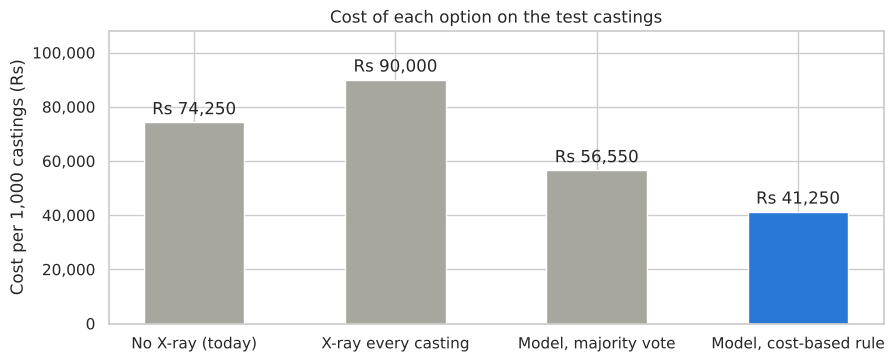

In [39]:
# Build the risk model with the K chosen for cost, and store all 2,400 training castings.
risk_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=cost_k))
risk_model.fit(X_train, y_train)

# The share of defective neighbours for each test casting.
test_share = risk_model.predict_proba(X_test)[:, 1]

# Flag a test casting when its share reaches the chosen threshold.
test_flag = test_share >= best_threshold - 1e-9

# The four outcomes at the new threshold.
caught_new = int((test_flag & (y_test == 1)).sum())
missed_new = int((~test_flag & (y_test == 1)).sum())
false_alarms_new = int((test_flag & (y_test == 0)).sum())

# The cost at the new threshold, per 1,000 castings.
cost_new = (test_flag.sum() * XRAY_COST + missed_new * MACHINING_COST) / len(y_test) * 1000

print(f"Rule used: K = {cost_k}, flag when {votes_needed} or more neighbours were defective")
print(f"Castings flagged for X-ray : {int(test_flag.sum())} of {len(y_test)} ({test_flag.mean() * 100:.0f}%)")
print(f"Defects caught             : {caught_new} of {int(y_test.sum())} ({caught_new / y_test.sum() * 100:.0f}%)   "
      f"[Scenario 27 caught {caught_defects}]")
print(f"Defects missed             : {missed_new}   [Scenario 27 missed {missed_defects}]")
print(f"False alarms               : {false_alarms_new}   [Scenario 27 had {false_alarms}]")

# All four options side by side.
all_options = dict(per_thousand)
all_options["D. Model, cost-based rule"] = cost_new    # add the new option to the three from Scenario 28

print()
for option, cost in all_options.items():
    print(f"{option:32s}: Rs {cost:,.0f} per 1,000 castings")

# The saving against today's situation, per 1,000 castings and per year.
saving_per_thousand = all_options["A. No X-ray (today)"] - cost_new
saving_per_year = saving_per_thousand / 1000 * CASTINGS_PER_YEAR
print(f"\nSaving against today : Rs {saving_per_thousand:,.0f} per 1,000 castings")
print(f"Estimated per year   : Rs {saving_per_year:,.0f} (about Rs {saving_per_year / 1e7:.1f} crore)")

# Draw the four options.
fig, ax = plt.subplots(figsize=(10, 3.8))
colours = [BLUE if cost == min(all_options.values()) else GREY for cost in all_options.values()]
bars = ax.bar([name.split(". ")[1] for name in all_options], list(all_options.values()), color=colours, width=0.5)
ax.bar_label(bars, fmt="Rs {:,.0f}", padding=3)
ax.set_ylabel("Cost per 1,000 castings (Rs)")
ax.set_title("Cost of each option on the test castings")
ax.set_ylim(0, max(all_options.values()) * 1.2)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
plt.show()

**Reading the output:** the rule was chosen without looking at the test castings. Applied to them:

| | Majority vote, K = 5 (Scenario 27) | Cost-based rule, K = 31 |
|---|---|---|
| Castings flagged for X-ray | 47 | **130** (22% of production) |
| Defects caught | 33 of 99 | **70 of 99 (71%)** |
| Defects missed | 66 | **29** |
| False alarms | 14 | 60 |

The model now catches more than twice as many defects. It also raises more false alarms: 60 instead of 14. That is the trade Anil asked for. Each false alarm costs ₹90. Each extra catch saves ₹450.

**Check the cost:** 130 X-rays × ₹90 = ₹11,700. 29 misses × ₹450 = ₹13,050. Total ₹24,750 for 600 castings = **₹41,250 per 1,000.**

**All four options, per 1,000 castings:**

- A. No X-ray (today): ₹74,250
- B. X-ray every casting: ₹90,000
- C. Model, majority vote: ₹56,550
- **D. Model, cost-based rule: ₹41,250**

Option D saves **₹33,000 per 1,000 castings** against today, a reduction of 44%. At 18,00,000 castings a year, that is about **₹5.9 crore a year**.

(Cross-validation predicted ₹37,313 and the test gives ₹41,250. As in Scenario 27, the figure chosen as the best of many options is slightly flattering. The test figure is the one to quote.)

**What changed between C and D:** the stored data is the same and the six columns are the same. We changed how many neighbours are consulted and where the cut-off sits, and we chose both by cost instead of by accuracy. Accuracy at the new rule is actually **lower**: 60 + 29 = 89 mistakes, against 80 before. The model makes more mistakes and saves far more money, because it now makes the cheap kind of mistake instead of the expensive kind.

**Business decision:** Anil has his number. X-raying about 22% of castings, chosen by the model, cuts the cost of defects by 44%, an estimated ₹5.9 crore a year. The yearly figure assumes this file is typical of the year and that the X-ray always finds a defect when there is one. The plant also needs X-ray capacity for about 1,300 castings a day (22% of 6,000).

## Scenario 30: "Check tomorrow's production plan before we run it"

**Who is asking:** Kiran, the production manager.

**The question:** "Here are six machine set-ups I am considering for tomorrow. Which of them are risky, and what would make them safer?"

**Why it matters to the business:** so far the model checked castings after they were made. It can also be used **before** production, to compare planned settings. Changing one setting at a time and watching the prediction is called a **what-if analysis**.

**What we will do:** write six planned set-ups as a table, prepare them exactly as we prepared the training data (cap with the training fences, create the Alloy-C column), and ask the model for the share of similar past castings that were defective. We call a set-up risky when the share reaches the threshold from Scenario 29.

The set-ups are chosen so that each one tests a specific question:

| Set-up | What it tests |
|---|---|
| 1 | The standard recipe on a freshly serviced die |
| 2 | The same recipe, but on a die with 85,000 shots on it |
| 3 | Set-up 2 after die maintenance (wear back to 2,000, vibration back to normal) |
| 4 | The standard recipe, but melt temperature has drifted up to 712 °C |
| 5 | Kiran's faster cycle from Scenario 14: cooling cut to 10 s, on a mid-life die, with Alloy-C |
| 6 | Set-up 5 with injection pressure raised to 960 bar to compensate |

In [40]:
# The six planned set-ups, written with the plant's own column names.
plan = pd.DataFrame({
    "melt_temperature_c":     [680,       680,       680,       712,       680,       680],
    "injection_pressure_bar": [900,       900,       900,       900,       900,       960],
    "cooling_time_sec":       [12.0,      12.0,      12.0,      12.0,      10.0,      10.0],
    "tool_wear_shots":        [5000,      85000,     2000,      5000,      30000,     30000],
    "vibration_mm_s":         [1.7,       3.0,       1.7,       1.7,       2.1,       2.1],
    "alloy_supplier":         ["Alloy-A", "Alloy-A", "Alloy-A", "Alloy-A", "Alloy-C", "Alloy-C"],
}, index=["Set-up 1", "Set-up 2", "Set-up 3", "Set-up 4", "Set-up 5", "Set-up 6"])


def prepare(castings):
    # Start from a copy so the original table is not changed.
    prepared = castings.copy()

    # Cap cooling time and vibration with the fences learned from the training set in Scenario 20.
    prepared[columns_to_cap] = prepared[columns_to_cap].clip(lower=fences["lower"], upper=fences["upper"], axis=1)

    # Create the Alloy-C column: 1 if the supplier is Alloy-C, otherwise 0.
    prepared["alloy_supplier_Alloy-C"] = (prepared["alloy_supplier"] == "Alloy-C").astype(int)

    # Return the 6 model columns in the order the model expects.
    return prepared[model_columns]


# Prepare the plan and ask the risk model for the share of defective neighbours for each set-up.
plan_ready = prepare(plan)
plan_share = risk_model.predict_proba(plan_ready)[:, 1]

# Take the two fitted steps out of the pipeline so that we can ask KNN for the neighbours themselves.
fitted_scaler = risk_model.named_steps["standardscaler"]
fitted_knn = risk_model.named_steps["kneighborsclassifier"]

# kneighbors() returns, for each set-up, the distances and row positions of its K most similar stored castings.
plan_distances, plan_positions = fitted_knn.kneighbors(fitted_scaler.transform(plan_ready))

# Add the results next to the settings.
plan_result = plan.copy()
plan_result["defective_neighbours"] = (plan_share * cost_k).round().astype(int)
plan_result["share_%"] = plan_share * 100

# The average distance to the neighbours: a small number means the plant has made many castings like this before.
plan_result["avg_distance"] = plan_distances.mean(axis=1)
plan_result["decision"] = np.where(plan_share >= best_threshold - 1e-9, "RISKY", "run as planned")

print(f"Rule: a set-up is RISKY when {votes_needed} or more of its {cost_k} most similar past castings were defective.\n")
plan_result

Rule: a set-up is RISKY when 6 or more of its 31 most similar past castings were defective.



,melt_temperature_c,injection_pressure_bar,cooling_time_sec,tool_wear_shots,vibration_mm_s,alloy_supplier,defective_neighbours,share_%,avg_distance,decision
Set-up 1,680,900,12.00,5000,1.70,Alloy-A,0,0.00,0.66,run as planned
Set-up 2,680,900,12.00,85000,3.00,Alloy-A,15,48.39,1.02,RISKY
Set-up 3,680,900,12.00,2000,1.70,Alloy-A,0,0.00,0.70,run as planned
Set-up 4,712,900,12.00,5000,1.70,Alloy-A,5,16.13,1.15,run as planned
Set-up 5,680,900,10.00,30000,2.10,Alloy-C,7,22.58,0.97,RISKY
Set-up 6,680,960,10.00,30000,2.10,Alloy-C,2,6.45,1.16,run as planned


**Reading the output:** each row is one planned set-up. `defective_neighbours` is how many of its 31 most similar past castings failed. A set-up is called RISKY at 6 or more.

- **Set-up 1 (standard recipe, fresh die): 0 of 31.** Run it.
- **Set-up 2 (same recipe, die at 85,000 shots): 15 of 31 (48%).** RISKY. Nothing changed except the die wear and the vibration that comes with it, and the share went from 0% to 48%.
- **Set-up 3 (set-up 2 after die maintenance): 0 of 31.** Back to safe. Comparing rows 2 and 3 shows what one maintenance shift is worth.
- **Set-up 4 (melt temperature 712 °C): 5 of 31 (16%).** Just under the cut-off, so the table says "run as planned". **Do not accept this one yet.** See below.
- **Set-up 5 (cooling cut to 10 s, mid-life die, Alloy-C, normal pressure): 7 of 31 (23%).** RISKY.
- **Set-up 6 (set-up 5 with pressure raised to 960 bar): 2 of 31 (6%).** Run as planned. Raising the pressure brought the faster cycle back under the cut-off, which agrees with what the grid in Scenario 14 showed.

**The `avg_distance` column** shows how similar the 31 neighbours really are. For Set-up 1 it is 0.66: the plant has made many castings just like this, so the neighbours are close and the answer is reliable. For Set-ups 4 and 6 it is about 1.15, nearly double. The plant has made few castings like these, so the model had to reach further to find 31 neighbours, and they are less similar. The answers for those two set-ups deserve less trust.

### Explain the riskiest set-up with its neighbours

When the model calls a set-up risky, the production manager will ask why. We show the actual past castings behind the prediction for Set-up 2. Then we look more closely at Set-up 4, whose result needs a second look.

In [41]:
# Set-up 2 is the second row of the plan, so its neighbours are at position 1 (counting starts at 0).
# Look up those castings in the training table, with a few extra columns for context.
context_columns = ["part_id", "machine_id"] + model_columns[:5] + ["alloy_supplier", "defect"]
setup_neighbours = train.iloc[plan_positions[1]][context_columns].copy()
setup_neighbours["distance"] = plan_distances[1]

print("Set-up 2:")
print(plan.loc[["Set-up 2"]].to_string())
print(f"\nIts {cost_k} most similar past castings (first 10 shown):")
print(setup_neighbours.head(10).to_string(index=False))
print(f"\nAll {cost_k} neighbours -> defective: {int(setup_neighbours['defect'].sum())}, "
      f"good: {int((setup_neighbours['defect'] == 0).sum())}")
print("Machines these neighbours came from:", setup_neighbours["machine_id"].value_counts().to_dict())

# A check on Set-up 4 (melt temperature 712): what melt temperatures did its neighbours actually have?
setup4_melt = train.iloc[plan_positions[3]]["melt_temperature_c"]
print(f"\nSet-up 4 asks about 712 degrees. Its {cost_k} neighbours had melt temperatures from "
      f"{setup4_melt.min():.0f} to {setup4_melt.max():.0f}, average {setup4_melt.mean():.0f}.")
print(f"Past castings above 710 degrees in the whole training set: {(train['melt_temperature_c'] > 710).sum()}")

Set-up 2:
          melt_temperature_c  injection_pressure_bar  cooling_time_sec  tool_wear_shots  vibration_mm_s alloy_supplier
Set-up 2                 680                     900             12.00            85000            3.00        Alloy-A

Its 31 most similar past castings (first 10 shown):
 part_id machine_id  melt_temperature_c  injection_pressure_bar  cooling_time_sec  tool_wear_shots  vibration_mm_s alloy_supplier  defect  distance
GH-01570      DC-03              681.50                  899.00             12.00            81562            3.28        Alloy-A       1      0.58
GH-01634      DC-03              680.80                  893.00             11.20            83906            2.74        Alloy-B       1      0.73
GH-01606      DC-03              677.80                  918.00             11.70            82268            3.30        Alloy-A       1      0.74
GH-01791      DC-03              679.90                  899.00             11.50            90506         

**Reading the output:**

**Set-up 2.** The 10 neighbours shown have melt temperatures of 672 to 686, pressures of 889 to 918, cooling times of 11.2 to 12.8 seconds, and tool wear between 72,308 and 94,210 shots. They match the planned set-up closely. Of all 31 neighbours, 15 were defective and 16 were good.

The last line says where they came from: **all 31 are from DC-03.** That follows from Scenario 12: DC-03 is the only machine that was ever run beyond 50,000 shots, so it is the only source of experience about badly worn dies. The model's answer for Set-up 2 is, in effect, "the last time the plant ran a die this worn, half the castings failed."

**Set-up 4.** We asked about 712 °C. The neighbours the model found were poured at **695 to 715 °C, with an average of 704**. In the whole training set there are only 39 castings above 710 °C. So the model could not find 31 castings like the one we asked about. It filled the list with cooler, safer castings, and that pulled the share down to 16%.

Scenario 13 gives the better answer for this set-up: castings poured above 705 °C failed **57%** of the time. The model's 16% is an underestimate.

**This is a general limit of KNN:** it can only answer from castings it has stored. For settings the plant has rarely or never used, the "nearest" castings are not actually near, and the prediction drifts towards what is common. The `avg_distance` column in the table above is the warning sign.

**Business decision for Kiran:**

- **Set-up 1 and 3:** run.
- **Set-up 2:** do not run. Service the die first (that is Set-up 3).
- **Set-up 4:** do not run, in spite of the table. Bring the furnace back inside 665 to 695 °C first. Where the model and a clear finding from the data disagree, and the model's neighbours are far away, trust the finding.
- **Set-up 5:** do not run.
- **Set-up 6:** promising, but the plant has little experience with it (average distance 1.16). Run it as a trial batch with every casting X-rayed, and add the results to the data.

---
# Summary

## What we told the plant

| # | Finding | Evidence | Recommended action |
|---|---|---|---|
| 1 | Defects waste about ₹13.3 crore of machining a year | 16.4% defect rate (Scenario 5) | Act on the items below |
| 2 | Worn dies are the largest single cause | 11.4% defective up to 40,000 shots, 37.5% beyond (Scenario 11) | Service every die at or before 40,000 shots |
| 3 | DC-03 is not a bad machine | Same defect rate as the others at the same wear (Scenario 12) | Do not buy a new machine (₹2.5 crore not spent) |
| 4 | Melt temperature has a safe window | 10.2% defective inside 665-695 °C, 32.3% outside (Scenario 13) | Set furnace alarms at 665 and 695 °C |
| 5 | Alloy-C costs more than it saves | Saves ₹6 per casting, wastes ₹48 (Scenario 9) | Do not renew on current terms |
| 6 | Short cooling needs high pressure | 27-35% defective at normal pressure, 10% above 940 bar (Scenario 14) | Trial the faster cycle only with pressure above 940 bar |
| 7 | The night shift is not the main cause | 19.4% against 14.6% in the morning (Scenarios 6 and 8) | Review, but do not expect a large gain |
| 8 | DC-02's die temperature sensor is failing | 12.4% of readings missing, against 1% elsewhere (Scenario 4) | Repair the sensor or its cable |
| 9 | A KNN model can direct X-ray checks | Cost falls from ₹74,250 to ₹41,250 per 1,000 castings on unseen castings (Scenario 29) | X-ray a casting when 6 or more of its 31 most similar past castings were defective |

Items 2 to 6 remove causes. Item 9 catches what is left. If the plant fixes the causes, the defect rate falls, and the model should then be rebuilt on the new data, because its stored castings would no longer represent how the plant runs.

## What each preparation step did for the model

| Step | Scenario | Result |
|---|---|---|
| Remove duplicates, fix labels, remove impossible readings | 1 to 3 | Correct counts and averages |
| Fill missing values with the training median | 19 | The model can predict when a sensor drops out |
| Cap cooling time and vibration at the IQR fences | 20, 25 | 23 more defects caught, 15 fewer false alarms |
| Leave tool wear uncapped | 17 | Its size is the information |
| Convert text to 0/1 columns | 21 | The supplier can be used |
| Scale | 22 | Without it, the model was worse than doing nothing (83.0%) |
| Choose 6 columns out of 18 | 23 | 85.5% → 88.7% |
| Choose K for accuracy | 26 | K = 5 |
| Choose K and threshold for cost | 29 | K = 31, flag at 6 of 31 |

## What this project shows about KNN

1. **KNN stores castings. It does not learn a formula.** Every prediction is a vote among the most similar stored castings, and those castings can be shown to the person who asks why.
2. **Everything depends on distance.** So anything that distorts distance damages the model: unscaled columns, extreme values that stretch the scale, and columns that have nothing to do with the outcome.
3. **KNN treats every column as equally important.** It cannot work out which ones matter. You have to decide, and the exploration in Part B is how you decide.
4. **KNN can use relationships that correlation cannot see.** Melt temperature has a correlation of 0.03 with defects and is still one of the most useful columns.
5. **The right K depends on the job.** K = 5 for the best majority vote. K = 31 for a steady estimate of risk.
6. **Accuracy can mislead when one class is rare.** The do-nothing score here was 83.5%. The model that saves the most money has a lower accuracy than the one that saves less.
7. **KNN is weak at the edges of its experience.** Where the plant has made few castings (Set-up 4), the neighbours are far away and the answer is unreliable. Check the distances.

## Practice tasks

1. **Another sensor code.** Suppose the vibration sensor writes `99.9` when it fails. Add a physically possible range for `vibration_mm_s` to Scenario 3 (ask yourself what that range should be, given Scenario 17) and rerun. How many readings does it catch?
2. **A different outlier rule.** In `iqr_fences`, change 1.5 to 3. This marks only extreme outliers. Rerun Scenarios 16 to 25. How many values are capped now, and does the result in Scenario 25 change?
3. **Cap the wrong column.** In Scenario 20, add `"tool_wear_shots"` to `columns_to_cap` and rerun to Scenario 25. What happens to the number of defects caught? Explain it using the tool wear chart in Scenario 17.
4. **Add the shift.** Add `"shift_Night"` to `model_columns` in Scenario 23 and rerun. Scenario 6 showed that Night has a higher defect rate. Does adding it help the model? Explain the result using point 3 in the list above.
5. **Split by time.** In Scenario 18, replace the random split with a time split: castings from weeks 1 to 9 for training, weeks 10 and 11 for testing (`df[df["week"] <= 9]` and `df[df["week"] > 9]`). Rerun to the end. Is the saving in Scenario 29 similar? Why is this a stricter check than a random split?
6. **Change the economics.** Suppose a cheaper X-ray service costs ₹45 per casting. Work out by hand what the threshold should be (use the formula in Scenario 29). Then change `XRAY_COST` in Scenario 5, rerun, and check whether Scenario 29 agrees with you.